# Moving-Average Trend Following in Crypto
## Technical Trading Rules — Grobys, Ahmed & Sapkota (2020)

**Strategy family: long-only trend following.** We compare each coin's log price with its
trailing average and hold cash when the trend turns unfavorable.

1. **Measure the trend.** Use the latest log close against its 20-, 50-, 100-, 150-, or 200-day mean.
2. **Hold the coin or cash.** Above the average means long; equality or below means cash.
3. **Trade the next return.** Today's decision earns tomorrow's close-to-close return.
4. **Keep capital separate.** Start with 30 equally funded coin sleeves. Cash stays in its own sleeve.

The authors favor the **(1, 20)** rule. We're checking all five horizons on the same 30 coins.
This is a later-sample application, rather than a reproduction of their 2016–2018 universe.

**Reference:** Grobys, Ahmed & Sapkota (2020), *Technical trading rules in the cryptocurrency market*.
[Published paper](https://doi.org/10.1016/j.frl.2019.101396).

**Fixed research dates:** prices from **2021-01-01 to 2026-09-17**;
backtest **2021-01-02 to 2024-12-31**; validation **2025-01-01 to 2026-09-17**.

Run in order from this notebook's folder. Input:
`OHLCV_Market_Cap_Data/crypto_30_coin_daily_ohlcv.csv`.
Packages: NumPy, pandas, SciPy, Matplotlib, statsmodels, and IPython.


## 1. Research design and experiment map

Same 30 coins, five horizons, and **20 bps per side** throughout. All rules wait for 200 price
observations in the main comparison; matched buy-and-hold starts at the same point.
Each period starts from cash and closes its remaining positions at the end.

**Selection rule:** highest backtest net cross-coin mean log payoff. Ties favor lower turnover,
then the shorter horizon. Freeze that choice before validation. Sharpe and CAGR help us read
the result, but don't choose a different winner.

We retain the paper's joint coin-level tests and BTC/ETH comparisons. Paired buy-and-hold
tests ask whether the rules add value beyond simply holding the coins.


In [1]:
from pathlib import Path
from io import BytesIO
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.api as sm
from IPython.display import display, Markdown

NOTEBOOK_NAME = "Technical_Trading_Rules_Grobys_et_al.ipynb"
# Input and output paths are relative to the extracted repository folder.
# Open that folder as your IDE project and start the kernel there.
NOTEBOOK_DIR = Path(".")
DATA_DIR = Path("OHLCV_Market_Cap_Data")
OUTPUT_ROOT = Path("output") / "technical_trading_rules"

SAMPLE_START = "2021-01-01"
SAMPLE_END = "2026-09-17"
BACKTEST_START, BACKTEST_END = "2021-01-02", "2024-12-31"
VALIDATION_START, VALIDATION_END = "2025-01-01", "2026-09-17"
#Same fixed research dates as Catching Crypto; the realized shares are shown below.

BTC_HAC_LAGS = 20
#The long moving-average horizons, similar to the paper. The short average is just one day.
LOOKBACKS = [20, 50, 100, 150, 200]
AUTHOR_HORIZON = 20
#Keep the authors' preferred rule as our reference.
#We wait for the longest horizon so all five rules get the same initial opportunity to trade.
COMMON_WARMUP = max(LOOKBACKS)

#20 bps on each side of a trade. Holding the same coin does not create another fee.
COST_BPS = 20
COST_RATE = COST_BPS / 10_000
PERIODS_PER_YEAR = 365
#Seven lags for the joint tests, separate from the BTC regression.
HAC_LAGS = 7

RULE_KEYS = [f"VMA_{n}" for n in LOOKBACKS]
PRIMARY_KEYS = RULE_KEYS + ["BH_MATCHED", "BH_FULL"]
LABELS = {f"VMA_{n}":f"VMA (1, {n})" for n in LOOKBACKS}
LABELS.update({"BH_MATCHED":"Buy & hold · matched start", "BH_FULL":"Buy & hold · full segment"})

RULE_COLORS = dict(zip(RULE_KEYS,["#176b87","#268779","#d08a35","#8555a6","#b35b66"]))
#A consistent color for each rule across the plots.

pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "#fcfcfd",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#d1d5db", "axes.labelcolor": "#374151", "text.color": "#1f2937",
    "xtick.color": "#64748b", "ytick.color": "#64748b", "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "grid.alpha": 0.25,
    "grid.color": "#cbd5e1", "legend.frameon": False,
})
FIGURES = {}

def polish_axis(ax, date_axis=False, zero_line=False):
    ax.grid(axis="y", linewidth=0.6)
    ax.set_axisbelow(True)
    if zero_line:
        ax.axhline(0, color="#64748b", linewidth=0.8, zorder=0)
    if date_axis:
        locator = mdates.AutoDateLocator(minticks=3, maxticks=8)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

def show_figure(fig, name, title, subtitle):
    height_points = fig.get_figheight()*72
    fig.text(0.06, 0.99, title, ha="left", va="top", fontsize=15)
    fig.text(0.06, 0.99-23/height_points, subtitle, va="top", fontsize=9, color="#64748b")
    fig.tight_layout(rect=[0.015, 0.015, 0.985, 0.99-43/height_points], w_pad=2.5, h_pad=2.5)
    FIGURES[name] = fig
    plt.show()
    plt.close(fig)


In [2]:
# Same 30 coins throghout, grouped here for quick review
SECTORS = {
    "Store of Value / Benchmark": ["BTC-USD"],
    "Layer 1 Smart Contracts": ["ETH-USD", "SOL-USD", "BNB-USD", "ADA-USD", "AVAX-USD", "DOT-USD", "NEAR-USD", "ATOM-USD", "TRX-USD", "ALGO-USD", "HBAR-USD"],
    "Payments & Legacy": ["XRP-USD", "DOGE-USD", "LTC-USD", "BCH-USD", "ETC-USD", "XLM-USD"],
    "DeFi Protocols": ["AAVE-USD", "MKR-USD", "UNI7083-USD", "CRV-USD", "INJ-USD", "RUNE-USD"],
    "Infrastructure, Storage & Metaverse": ["LINK-USD", "FIL-USD", "VET-USD", "THETA-USD", "SAND-USD", "MANA-USD"]
}

#Same 30 coins throughout. UNI7083 is just mapped back to the usual UNI label.
#Bring the groups into one ticker list.
tickers = [t for members in SECTORS.values() for t in members] 
#Use the usual UNI label and keep the coin order consistent.
ASSETS = sorted("UNI-USD" if t == "UNI7083-USD" else t for t in tickers)
#Quick check: 30 coins, with no duplicates.
assert len(ASSETS) == len(set(ASSETS)) == 30
display(pd.DataFrame([{"Category": sector, "Coins": ", ".join(t.replace("7083", "").replace("-USD", "") for t in members)}
                      for sector, members in SECTORS.items()]))


,Category,Coins
0,Store of Value / Benchmark,BTC
1,Layer 1 Smart Contracts,"ETH, SOL, BNB, ADA, AVAX, DOT, NEAR, ATOM, TRX..."
2,Payments & Legacy,"XRP, DOGE, LTC, BCH, ETC, XLM"
3,DeFi Protocols,"AAVE, MKR, UNI, CRV, INJ, RUNE"
4,"Infrastructure, Storage & Metaverse","LINK, FIL, VET, THETA, SAND, MANA"


In [3]:
#Time to input everything from the csv files. Coin prices are already downloaded into OHLCV_Market_Cap_Data/crypto_30_coin_daily_ohlcv.csv

INPUT_PATH = DATA_DIR / "crypto_30_coin_daily_ohlcv.csv"
if not INPUT_PATH.is_file():
    raise FileNotFoundError(
        f"Missing bundled input: {INPUT_PATH.relative_to(NOTEBOOK_DIR).as_posix()}. "
        "Open the fully extracted repository folder as your IDE project and set the kernel working directory there. "
        "If this folder is already correct, restore the missing CSV from the repository input files."
    )

# Hash and parse the same bytes; the run manifest records the exact CSV used.
#Record the file hash so we know which data this run used.
input_bytes = INPUT_PATH.read_bytes()
input_hashes = {INPUT_PATH.name: hashlib.sha256(input_bytes).hexdigest()}
#Match our ticker labels, then arrange dates as rows and coins as columns.
market_data = pd.read_csv(BytesIO(input_bytes))
#Check the columns, dates, and coin names before going further.
required_columns = {"date", "symbol", "open", "high", "low", "close", "volume"}
if not required_columns.issubset(market_data.columns):
    raise ValueError(f"Missing input columns: {sorted(required_columns - set(market_data.columns))}")
market_data["date"] = pd.to_datetime(market_data["date"], format="%Y-%m-%d", errors="raise")
if market_data["date"].isna().any() or market_data["symbol"].isna().any():
    raise ValueError("Missing dates or symbols in the input CSV.")
if market_data.duplicated(["date", "symbol"]).any():
    raise ValueError("Duplicate date/symbol observations in the input CSV.")
expected_symbols = {asset.removesuffix("-USD") for asset in ASSETS}
if set(market_data["symbol"]) != expected_symbols:
    raise ValueError("Input CSV must contain exactly the fixed 30-coin universe.")
for field in ["close", "volume"]:
    market_data[field] = pd.to_numeric(market_data[field], errors="raise")

# Preserve the strategy's established asset labels, including UNI-USD.
market_data["asset"] = market_data["symbol"] + "-USD"
prices = market_data.pivot(index="date", columns="asset", values="close").sort_index()
volume = market_data.pivot(index="date", columns="asset", values="volume").sort_index()
# Explicit sample dates below exclude unavailable observations beyond this study.
for label, frame in [("prices", prices), ("volume", volume)]:
    if set(frame.columns) != set(ASSETS):
        raise ValueError(f"{label}: input must contain exactly the fixed 30 assets.")
    if not frame.index.is_unique or not frame.index.is_monotonic_increasing:
        raise ValueError(f"{label}: dates must be sorted and unique.")
#Keep the same sample dates and coin order for both panels.
prices = prices.loc[SAMPLE_START:SAMPLE_END, ASSETS].copy()
volume = volume.loc[SAMPLE_START:SAMPLE_END, ASSETS].copy()
if not prices.index.equals(volume.index):
    raise ValueError("Price and volume dates differ.")
expected_calendar = pd.date_range(SAMPLE_START, SAMPLE_END, freq="D")
#We need every calendar day, with no missing or invalid prices.
if not prices.index.equals(expected_calendar):
    raise ValueError("Snapshot must contain every calendar day in the declared sample.")
if not np.isfinite(prices.to_numpy()).all() or (prices <= 0).any().any():
    raise ValueError("Nonpositive or missing prices require a data review; no price imputation.")

#Daily price returns; the first date has no previous close to compare with.
returns = prices.pct_change(fill_method=None).iloc[1:]
PERIOD_DATES = {
    "Backtest": returns.loc[BACKTEST_START:BACKTEST_END].index,
    "Validation": returns.loc[VALIDATION_START:VALIDATION_END].index,
}
bad_volume = ~np.isfinite(volume) | (volume <= 0)
bad_rows, bad_cols = np.where(bad_volume.to_numpy())
volume_issues = pd.DataFrame({
    "date": volume.index[bad_rows], "asset": volume.columns[bad_cols],
    "observed_volume": volume.to_numpy()[bad_rows, bad_cols],
})
assert PERIOD_DATES["Backtest"].append(PERIOD_DATES["Validation"]).equals(returns.index)
print(f"Loaded {len(ASSETS)} coins and {len(prices):,} daily prices from {SAMPLE_START} through {SAMPLE_END}.")
display(prices.head())
#Keep the provider labels visible; the supplied snapshot includes a few fallback rows.
if "ohlcv_source" in market_data.columns:
    display(market_data.loc[market_data["date"].between(SAMPLE_START, SAMPLE_END), "ohlcv_source"].value_counts().rename("Observations").to_frame())
display(volume_issues)


#Record the split and check that the two periods cover every return date once.
split_table = pd.DataFrame([
    {"Period": label, "First return": dates[0].date(), "Last return": dates[-1].date(),
     "Dates": len(dates), "Share of dates (%)": 100 * len(dates) / len(returns)}
    for label, dates in PERIOD_DATES.items()
]).set_index("Period")
assert len(PERIOD_DATES["Backtest"].intersection(PERIOD_DATES["Validation"])) == 0
assert PERIOD_DATES["Backtest"].append(PERIOD_DATES["Validation"]).equals(returns.index)
assert PERIOD_DATES["Backtest"][-1] < PERIOD_DATES["Validation"][0]


Loaded 30 coins and 2,086 daily prices from 2021-01-01 through 2026-09-17.


asset,AAVE-USD,ADA-USD,ALGO-USD,ATOM-USD,AVAX-USD,BCH-USD,BNB-USD,BTC-USD,CRV-USD,DOGE-USD,...,NEAR-USD,RUNE-USD,SAND-USD,SOL-USD,THETA-USD,TRX-USD,UNI-USD,VET-USD,XLM-USD,XRP-USD
date,,,,,,,,,,,,,,,,,,,,,
2021-01-01,90.3497,0.1753,0.3981,5.8686,3.6648,341.9856,37.9050,29374.1519,0.6223,0.0057,...,1.3573,1.2940,0.0370,1.8421,1.9715,0.0269,4.7362,0.0191,0.1324,0.2374
2021-01-02,85.7128,0.1774,0.4081,5.4146,3.4949,354.5999,38.2416,32127.2679,0.6142,0.0106,...,1.4097,1.2934,0.0381,1.7993,2.4004,0.0272,4.8452,0.0200,0.1278,0.2217
2021-01-03,91.0966,0.2050,0.4228,5.8139,3.4729,421.7899,41.1490,32782.0245,0.6723,0.0098,...,1.4727,1.4815,0.0410,2.1618,2.1214,0.0295,5.4470,0.0259,0.1364,0.2258
2021-01-04,111.1320,0.2248,0.4387,5.9968,3.5902,407.9369,40.9264,31971.9135,0.6770,0.0098,...,1.3837,1.5902,0.0405,2.4851,1.9603,0.0309,5.4066,0.0247,0.1652,0.2367
2021-01-05,116.4538,0.2583,0.4794,6.2168,4.2374,419.7681,41.7346,33992.4293,0.6870,0.0099,...,1.5020,1.5842,0.0418,2.1572,2.1340,0.0286,6.2793,0.0279,0.1948,0.2268


,Observations
ohlcv_source,
coinmarketcap,62575
yahoo_finance_cmc_fallback,5


,date,asset,observed_volume
0,2026-09-07,MKR-USD,0.0000
1,2026-09-12,MKR-USD,0.0000


## 2. Moving averages and signal timing

For price $P_{i,t}$ and lookback $n$, define

$$x_{i,t}=\ln P_{i,t},\qquad MA_{i,t}(n)=\frac{1}{n}\sum_{k=0}^{n-1}x_{i,t-k},
\qquad S_{i,t}(n)=\mathbf{1}\{x_{i,t}>MA_{i,t}(n)\}.$$

The decision at $t$ earns the return from $t$ to $t+1$. For a frictionless single-coin sleeve,
the simple return is $S_{i,t} (P_{i,t+1}/P_{i,t}-1)$ and the log return is
$S_{i,t}(\ln P_{i,t+1}-\ln P_{i,t})$. The signal is a **state**, so it stays long until
the condition becomes false; it is not a one-day trade on the crossing alone.

The rule compares price with a **geometric** mean of past prices, because the moving average
is formed in log space. It is not an exponential average, an arithmetic-price average, or a
volatility-adjusted indicator. Natural logarithms are used explicitly. The paper writes “log”
without stating its base; a different positive logarithm base rescales log means and their
annual rates, but does not change crossover decisions or standardized t/Wald statistics.

We assume trading at the formation close after observing that close. This is a daily-bar
backtest convention, not a claim of frictionless live access to the exact final quote.
The stated 20 bps is the entire modeled trading friction; cash interest is zero.

### Equation-to-code map

| Strategy symbol | Code variable | Meaning |
|---|---|---|
| $P_{i,t}$ | `prices` / `price_frame` | Closing price of each coin |
| $x_{i,t}=\ln P_{i,t}$ | `log_prices` / `logs` | Natural-log closing price |
| $MA_{i,t}(n)$ | `moving_averages[n]` / `ma` | Mean of the latest $n$ log closes, including today |
| History available | `common_ready` / `ready` / `valid` | Dates on which the selected warm-up permits a decision |
| $S_{i,t}(n)$ | `output[f"VMA_{n}"]` | Long or cash decision made at today's close |
| $r_{i,t}$ | `returns` | Daily simple price return |
| $\ell_{i,t}$ | `log_returns` | Daily natural-log price return |

The core signal is binary: **1 means hold the coin, 0 means hold cash**. We don't need to z-score the signal here; each coin is compared with its own trailing average. The comments below place the mathematical quantities beside their calculations.


In [4]:
#x_i_t: natural log of the closing price for every date and coin.
#Work with log prices and log returns.
log_prices=np.log(prices)
log_returns=np.log1p(returns)
#MA_i_t(n): trailing mean log price, including the current close.
#Calculate each trailing average, including today's close.
moving_averages={n:log_prices.rolling(n,min_periods=n).mean() for n in LOOKBACKS}
#All rules wait until the 200-day moving average exists.
#Wait until all coins have enough history for the longest average.
common_ready=moving_averages[COMMON_WARMUP].notna().all(axis=1)

def make_signals(price_frame,convention="common"):
    #Just the closing-price frame in log space.
    #Compare each coin with its own price history.
    logs=np.log(price_frame)
    ready=logs.rolling(COMMON_WARMUP,min_periods=COMMON_WARMUP).mean().notna().all(axis=1)
    output={}
    for n in LOOKBACKS:
        #The long average changes with n. The one-day short average is logs itself.
        ma=logs.rolling(n,min_periods=n).mean()
        #Common waits 200 days; native waits only for this particular horizon.
        #Today's log close is our short average; n sets the long average.
        valid=ready if convention=="common" else ma.notna().all(axis=1)
        #S_i_t(n): 1 means long, 0 means cash. Equality also leaves the sleeve in cash.
        output[f"VMA_{n}"]=(logs>ma).where(valid,False,axis=0).astype(float)
    #Matched buy-and-hold waits for the same history; full buy-and-hold starts immediately.
    if convention=="common":
        output["BH_MATCHED"]=pd.DataFrame(np.repeat(ready.to_numpy()[:,None],len(ASSETS),axis=1),
                                         index=price_frame.index,columns=ASSETS).astype(float)
        output["BH_FULL"]=pd.DataFrame(1.,index=price_frame.index,columns=ASSETS)
    return output

#Generate both warm-up conventions without changing any of the horizon choices.
#Build both versions so we can check whether the starting history matters.
signals={mode:make_signals(prices,mode) for mode in ["common","native"]}
#Show when each rule can first form a signal and earn a return.
start_rows=[]
for n in LOOKBACKS:
    native=moving_averages[n].notna().all(axis=1)
    start_rows.append({"Lookback":n,"Native first formation":native[native].index[0].date(),
        "Common first formation":common_ready[common_ready].index[0].date(),
        "Common first holding return":(common_ready[common_ready].index[0]+pd.Timedelta(days=1)).date()})
display(pd.DataFrame(start_rows).set_index("Lookback"))


,Native first formation,Common first formation,Common first holding return
Lookback,,,
20,2021-01-20,2021-07-19,2021-07-20
50,2021-02-19,2021-07-19,2021-07-20
100,2021-04-10,2021-07-19,2021-07-20
150,2021-05-30,2021-07-19,2021-07-20
200,2021-07-19,2021-07-19,2021-07-20


### Signal state versus a trade

A 1 means stay long, not buy again each day. We trade only when the state changes.
The BTC example shows a fast and a slow average. The bottom panel counts long signals;
it isn't the portfolio's invested weight, since sleeve values drift.


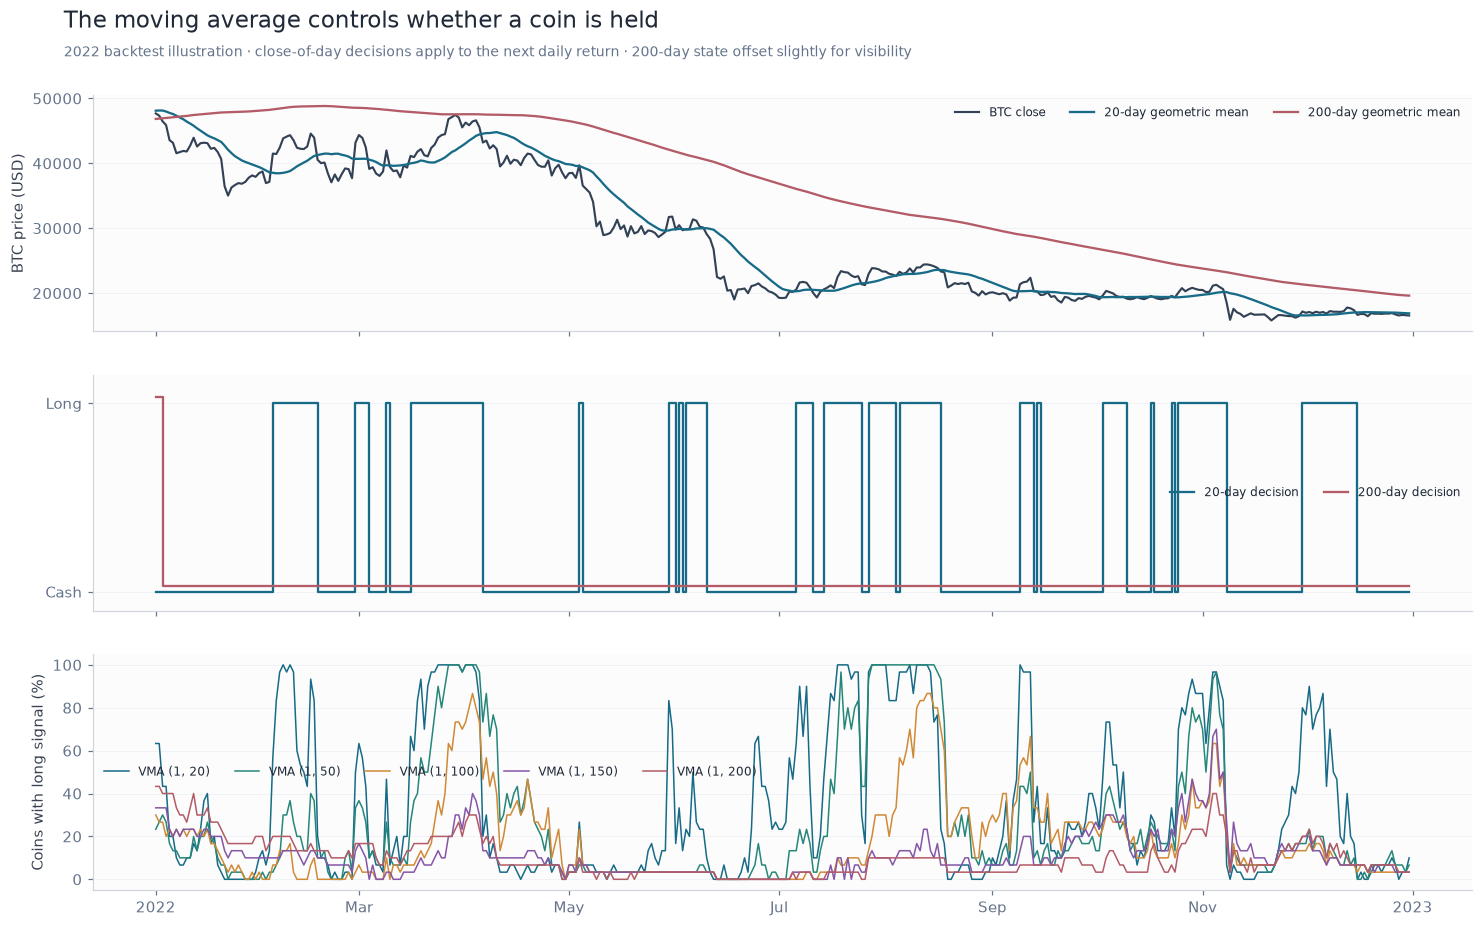

In [5]:
#Fixed instructional window, used only to show how the signal behaves.
window=prices.index[(prices.index>="2022-01-01")&(prices.index<="2022-12-31")]
fig,axes=plt.subplots(3,1,figsize=(14,8.6),sharex=True)
axes[0].plot(window,prices.loc[window,"BTC-USD"],color="#334155",lw=1.4,label="BTC close")
#Compare a fast and a slow average. The plotted averages are converted back to price units.
for n in [20,200]:
    axes[0].plot(window,np.exp(moving_averages[n].loc[window,"BTC-USD"]),color=RULE_COLORS[f"VMA_{n}"],label=f"{n}-day geometric mean")
axes[0].set_ylabel("BTC price (USD)");axes[0].legend(ncol=3,fontsize=8)
for n in [20,200]:
    axes[1].step(window,signals["common"][f"VMA_{n}"].loc[window,"BTC-USD"]+(0.03 if n==200 else 0),
                 where="post",color=RULE_COLORS[f"VMA_{n}"],label=f"{n}-day decision" )
axes[1].set_yticks([0,1],["Cash","Long"]);axes[1].set_ylim(-.1,1.15);axes[1].legend(ncol=2,fontsize=8)
for key in RULE_KEYS:
    axes[2].plot(window,100*signals["common"][key].loc[window].mean(axis=1),color=RULE_COLORS[key],lw=1,label=LABELS[key])
axes[2].set_ylabel("Coins with long signal (%)");axes[2].legend(ncol=5,fontsize=8)
for ax in axes:polish_axis(ax,date_axis=True)
show_figure(fig,"signal_walkthrough","The moving average controls whether a coin is held","2022 backtest illustration · close-of-day decisions apply to the next daily return · 200-day state offset slightly for visibility")


## 3. Execution and the fixed 20-bps fee

Each sleeve starts with one unit of cash. A buy invests $V/(1+c)$ from cash $V$;
a sale returns $A(1-c)$ from asset value $A$, with $c=0.002$.
A continuing position keeps the same units. Final liquidation also pays the fee.

`simulate` aligns the previous close's decision with today's return. Gross and net use
separate accounting paths. There is no leverage, shorting, or transfer between sleeves.
We assume execution at the signal close and zero cash interest.


In [6]:
def sleeve_account(positions,asset_returns,dates,cost_rate,assets):
    #positions already contains the previous close decision for each return date.
    pos=np.asarray(positions,dtype=bool);r=np.asarray(asset_returns,dtype=float)
    t_count,n=r.shape
    #Each coin starts with one unit of cash. risky records asset value, not a target weight.
    risky=np.zeros(n);cash=np.ones(n);state=np.zeros(n,dtype=bool)
    #These arrays keep the complete record of every coin across all return dates.
    coin_returns=np.zeros_like(r);coin_nav=np.zeros_like(r)
    holding=np.zeros_like(r);allocation=np.zeros_like(r);pnl_contrib=np.zeros_like(r)
    fee_contrib=np.zeros_like(r);traded=np.zeros_like(r)
    record=[];trade_rows=[];opened={}
    for t,date in enumerate(dates):
        #Beginning equity, before trading fees and today's price move.
        prior=risky+cash;total=prior.sum();decision=pos[t]
        #Trade only when the state changes. A continuing long keeps the same coin units.
        buy=decision&~state;sell=~decision&state
        trade=np.zeros(n);fees=np.zeros(n)
        #Sell the existing asset value and leave the proceeds, less the fee, in this sleeve.
        if sell.any():
            trade[sell]=risky[sell];fees[sell]=cost_rate*risky[sell]
            cash[sell]+=risky[sell]-fees[sell];risky[sell]=0
        #A + c*A = cash, so the amount we can actually invest is cash/(1+c).
        if buy.any():
            risky[buy]=cash[buy]/(1+cost_rate)
            trade[buy]=risky[buy];fees[buy]=cost_rate*risky[buy];cash[buy]=0
        post=risky+cash
        #holding is risky exposure after trading; allocation includes the sleeve's cash before trading.
        holding[t]=risky/post.sum();allocation[t]=prior/total
        #Apply today's return to the asset value bought or carried from the previous close.
        pnl=risky*r[t];risky+=pnl
        #The return date is one day after the modeled entry close.
        for i in np.flatnonzero(buy):
            opened[i]=(date-pd.Timedelta(days=1),prior[i])
        for i in np.flatnonzero(sell):
            entry_date,entry_nav=opened.pop(i)
            trade_rows.append({"Asset":assets[i],"Entry close":entry_date,"Exit close":date-pd.Timedelta(days=1),
                "Holding days":(date-pd.Timedelta(days=1)-entry_date).days,
                "Trade return":cash[i]/entry_nav-1,"Exit reason":"Signal"})
        terminal=np.zeros(n)
        #Close the remaining positions at the segment end, including the final selling fee.
        if t==t_count-1:
            terminal=risky.copy();fees+=cost_rate*terminal;trade+=terminal
            cash+=risky*(1-cost_rate);risky[:]=0
            for i in list(opened):
                entry_date,entry_nav=opened.pop(i)
                trade_rows.append({"Asset":assets[i],"Entry close":entry_date,"Exit close":date,
                    "Holding days":(date-entry_date).days,"Trade return":cash[i]/entry_nav-1,"Exit reason":"Segment end"})
        nav=risky+cash
        if not np.isfinite(nav).all() or (nav<=0).any():raise ArithmeticError("Nonpositive or invalid sleeve equity")
        coin_returns[t]=nav/prior-1;coin_nav[t]=nav
        #Scale P&L, fees and traded dollars by the same beginning portfolio equity.
        pnl_contrib[t]=pnl/total;fee_contrib[t]=fees/total;traded[t]=trade/total
        record.append({"return":nav.sum()/total-1,"nav":nav.mean(),"asset_pnl":pnl.sum()/total,
            "fee":fees.sum()/total,"turnover":trade.sum()/total,"gross_exposure":holding[t].sum(),
            "active_coins":decision.sum(),"entries":buy.sum(),"signal_exits":sell.sum(),"terminal_turnover":terminal.sum()/total})
        #Carry today's decision into the next iteration so we can identify a change of state.
        state=decision.copy()
    frame=pd.DataFrame(record,index=dates)
    detail={name:pd.DataFrame(values,index=dates,columns=assets) for name,values in [
        ("coin_returns",coin_returns),("coin_nav",coin_nav),("holding_weights",holding),
        ("sleeve_allocations",allocation),("pnl_contributions",pnl_contrib),
        ("fee_contributions",fee_contrib),("traded_notional",traded)]}
    return {"daily":frame,**detail,"trades":pd.DataFrame(trade_rows)}


def simulate(period,key,mode="common",basis="net"):
    dates=PERIOD_DATES[period]
    #S_i,t-1 earns r_i,t. This date alignment is where the signal becomes an actual holding.
    pos=signals[mode][key].reindex(dates-pd.Timedelta(days=1)).to_numpy()
    return sleeve_account(pos,returns.loc[dates].to_numpy(),dates,COST_RATE if basis=="net" else 0.,ASSETS)


## 4. Backtest selection and validation

First run the backtest, freeze the winner, then evaluate validation.
The paper-style payoff averages annualized log returns across coins. Portfolio CAGR instead
compounds the funded sleeves; these answer different questions.

Daily statistics include cash days and use 365 days per year. Drawdown includes initial capital.
The small checks below cover timing, costs, and the coin-to-portfolio reconciliation.


In [7]:
def wealth_drawdown(r):
    #Compound the daily portfolio returns; the initial capital of one remains a drawdown reference.
    wealth=(1+r).cumprod()
    return wealth,wealth/wealth.cummax().clip(lower=1)-1

def account_metrics(result):
    f=result["daily"];r=f["return"];wealth,dd=wealth_drawdown(r)
    sd=r.std(ddof=1);downside=np.sqrt(np.mean(np.minimum(r,0)**2))
    logs=np.log1p(result["coin_returns"])
    return {"Dates":len(r),"Cross-coin annual mean log (%)":36500*logs.mean().mean(),
        "Portfolio CAGR (%)":100*(wealth.iloc[-1]**(365/len(r))-1),
        "Portfolio total return (%)":100*(wealth.iloc[-1]-1),"Portfolio annual mean simple (%)":36500*r.mean(),
        "Portfolio volatility (%)":100*sd*np.sqrt(365),"Portfolio Sharpe":np.sqrt(365)*r.mean()/sd if sd>0 else np.nan,
        "Portfolio Sortino":np.sqrt(365)*r.mean()/downside if downside>0 else np.nan,
        "Portfolio max drawdown (%)":100*dd.min(),"Mean invested (%)":100*f.gross_exposure.mean(),
        "Annual turnover":365*f.turnover.mean(),"Annual fees (%)":36500*f.fee.mean(),
        "Cash-only dates":int((f.gross_exposure<1e-12).sum())}


checks=[]
def check(name,condition):
    if not bool(condition):raise AssertionError(name)
    checks.append({"Check":name,"Result":"PASS"})
check("Fixed 30 coins and reference calendar",len(ASSETS)==30 and
      PERIOD_DATES["Backtest"].equals(pd.date_range(BACKTEST_START,BACKTEST_END)) and
      PERIOD_DATES["Validation"].equals(pd.date_range(VALIDATION_START,VALIDATION_END)) and
      PERIOD_DATES["Backtest"].append(PERIOD_DATES["Validation"]).equals(returns.index))
sample_date=prices.index[300]
manual=np.log(prices.loc[:sample_date,"BTC-USD"].tail(20)).mean()
construction=np.isclose(manual,moving_averages[20].loc[sample_date,"BTC-USD"])
construction=construction and all(np.isin(v.to_numpy(),[0.,1.]).all() for v in signals["common"].values())
construction=construction and all(v.loc[~common_ready].eq(0).all().all() for k,v in signals["common"].items() if k!="BH_FULL")
check("Log-price moving averages, binary states and common warm-up",construction)
#Change future prices and check that earlier decisions stay exactly the same.
boundary=PERIOD_DATES["Validation"][0];changed=prices.copy()
changed.loc[boundary:]*=np.linspace(.7,1.8,30)
changed_signals=make_signals(changed)
check("Future observations cannot change earlier decisions",all(signals["common"][k].loc[prices.index<boundary].equals(
    changed_signals[k].loc[prices.index<boundary]) for k in PRIMARY_KEYS))
#A small hand-checkable account: buy, hold, sell, then stay in cash.
toy_dates=pd.date_range("2000-01-02",periods=4)
toy=sleeve_account(np.array([[1],[1],[0],[0]]),np.array([[.1],[.1],[.5],[0.]]),toy_dates,COST_RATE,["TEST"])
expected=1.21*(1-COST_RATE)/(1+COST_RATE)
check("Fixed units, exact entry/exit costs and cash retention",np.isclose(toy["daily"].nav.iloc[-1],expected) and
      toy["daily"].turnover.iloc[[1,3]].eq(0).all() and np.allclose(toy["daily"]["return"],toy["daily"].asset_pnl-toy["daily"].fee))
#Without fees, each coin's log payoff should equal its lagged state times the coin log return.
sample=simulate("Backtest","VMA_20",basis="gross")
pos=signals["common"]["VMA_20"].shift(1).loc[PERIOD_DATES["Backtest"]]
check("Gross sleeve payoffs and investable portfolio aggregation",np.allclose(np.log1p(sample["coin_returns"]),pos*log_returns.loc[pos.index]) and
      np.allclose(sample["daily"].nav,sample["coin_nav"].mean(axis=1)) and
      np.allclose((1+sample["daily"]["return"]).cumprod(),sample["daily"].nav))
verification=pd.DataFrame(checks)
print(f"{len(verification)} core checks passed.")


#Run every declared rule, keeping gross and net accounts separate.
accounts={};metric_rows=[]
def evaluate(period):
    for mode,keys in [("common",PRIMARY_KEYS),("native",RULE_KEYS)]:
        for key in keys:
            for basis in ["gross","net"]:
                result=simulate(period,key,mode,basis)
                accounts[(period,mode,key,basis)]=result
                metric_rows.append({"Period":period,"Warm-up":mode,"Strategy":key,"Basis":basis,**account_metrics(result)})

#First compare the backtest results. Validation has not been evaluated yet.
evaluate("Backtest")
training=pd.DataFrame(metric_rows)
ranking=training.query("`Warm-up`=='common' and Basis=='net' and Strategy in @RULE_KEYS").set_index("Strategy")
ranking=ranking[["Cross-coin annual mean log (%)","Annual turnover","Portfolio CAGR (%)","Portfolio Sharpe"]].copy()
ranking["Lookback"]=[int(k.split("_")[1]) for k in ranking.index]
#Highest net average log payoff wins; turnover and lookback settle exact ties.
ranking=ranking.sort_values(["Cross-coin annual mean log (%)","Annual turnover","Lookback"],ascending=[False,True,True],kind="stable")
selected_key=ranking.index[0]
gross_ranking=training.query("`Warm-up`=='common' and Basis=='gross' and Strategy in @RULE_KEYS").sort_values(
    ["Cross-coin annual mean log (%)","Annual turnover","Strategy"],ascending=[False,True,True],kind="stable")
gross_winner=gross_ranking.iloc[0].Strategy
#Keep a record of this choice before looking at validation.
frozen_selection={"strategy":selected_key,"criterion":"Highest backtest cross-coin annual mean natural-log return, net 20 bps, common warm-up",
    "tie_break":"Lower turnover, then shorter lookback","author_reference":"VMA_20","backtest_gross_winner":gross_winner,
    "backtest_end":str(PERIOD_DATES["Backtest"][-1].date()),"candidates":RULE_KEYS}
print("Selection frozen before validation:",LABELS[selected_key])
display(ranking.rename(index=LABELS))
#Now evaluate the remaining dates with the selected horizon already fixed.
evaluate("Validation")
metrics=pd.DataFrame(metric_rows).set_index(["Period","Warm-up","Strategy","Basis"]).sort_index()
#These alternative rankings help interpret the results; they do not select a new strategy.
winner_rows=[]
for period in PERIOD_DATES:
    for mode in ["common","native"]:
        for basis in ["gross","net"]:
            table=metrics.xs((period,mode,basis),level=("Period","Warm-up","Basis")).reindex(RULE_KEYS)
            for criterion in ["Cross-coin annual mean log (%)","Portfolio CAGR (%)","Portfolio Sharpe"]:
                winner=table[criterion].idxmax()
                winner_rows.append({"Period":period,"Warm-up":mode,"Basis":basis,"Criterion":criterion,
                    "Best observed rule":winner,"Best observed value":table.loc[winner,criterion],
                    "Author 20-day rank":int(table[criterion].rank(ascending=False,method="min").loc["VMA_20"])})
winner_comparison=pd.DataFrame(winner_rows).set_index(["Period","Warm-up","Basis","Criterion"]).sort_index()
print(f"Completed {len(accounts)} accounts across both periods, gross/net, and warm-up conventions.")


5 core checks passed.


Selection frozen before validation: VMA (1, 20)


,Cross-coin annual mean log (%),Annual turnover,Portfolio CAGR (%),Portfolio Sharpe,Lookback
Strategy,,,,,
"VMA (1, 20)",21.2647,31.4655,43.0285,1.0507,20
"VMA (1, 50)",15.7200,17.5971,32.9353,0.8612,50
"VMA (1, 150)",10.9772,9.2152,23.3897,0.7003,150
"VMA (1, 200)",7.7619,8.8903,21.2229,0.6585,200
"VMA (1, 100)",6.9901,13.2447,19.1703,0.6166,100


Completed 48 accounts across both periods, gross/net, and warm-up conventions.


## 5. Horizon comparisons

Let's compare all five rules, including the authors' 20-day choice. Gross versus net shows
how much trading costs matter. The matched buy-and-hold line uses the same starting history.
Only the declared backtest log-payoff criterion selects the winner.


Best observed rule  \
Period     Warm-up Basis Criterion                                           
Backtest   common  gross Cross-coin annual mean log (%)             VMA_20   
                         Portfolio CAGR (%)                         VMA_20   
                         Portfolio Sharpe                           VMA_20   
                   net   Cross-coin annual mean log (%)             VMA_20   
                         Portfolio CAGR (%)                         VMA_20   
                         Portfolio Sharpe                           VMA_20   
           native  gross Cross-coin annual mean log (%)             VMA_20   
                         Portfolio CAGR (%)                         VMA_20   
                         Portfolio Sharpe                           VMA_20   
                   net   Cross-coin annual mean log (%)             VMA_20   
                         Portfolio CAGR (%)                         VMA_20   
                         Portfolio Sharpe                           VMA_20   
Validation common  gross Cross-coin annual mean log (%)            VMA_100   
                         Portfolio CAGR (%)                         VMA_50   
                         Portfolio Sharpe                           VMA_50   
                   net   Cross-coin annual mean log (%)            VMA_100   
                         Portfolio CAGR (%)                        VMA_100   
                         Portfolio Sharpe                          VMA_100   
           native  gross Cross-coin annual mean log (%)            VMA_100   
                         Portfolio CAGR (%)                         VMA_50   
                         Portfolio Sharpe                           VMA_50   
                   net   Cross-coin annual mean log (%)            VMA_100   
                         Portfolio CAGR (%)                        VMA_100   
                         Portfolio Sharpe                          VMA_100   

                                                         Best observed value  \
Period     Warm-up Basis Criterion                                             
Backtest   common  gross Cross-coin annual mean log (%)              28.1414   
                         Portfolio CAGR (%)                          52.1577   
                         Portfolio Sharpe                             1.1973   
                   net   Cross-coin annual mean log (%)              21.2647   
                         Portfolio CAGR (%)                          43.0285   
                         Portfolio Sharpe                             1.0507   
           native  gross Cross-coin annual mean log (%)              41.2264   
                         Portfolio CAGR (%)                          84.4702   
                         Portfolio Sharpe                             1.4729   
                   net   Cross-coin annual mean log (%)              33.2830   
                         Portfolio CAGR (%)                          71.1195   
                         Portfolio Sharpe                             1.3235   
Validation common  gross Cross-coin annual mean log (%)             -22.3229   
                         Portfolio CAGR (%)                         -13.6384   
                         Portfolio Sharpe                            -0.3175   
                   net   Cross-coin annual mean log (%)             -25.7490   
                         Portfolio CAGR (%)                         -17.3369   
                         Portfolio Sharpe                            -0.4253   
           native  gross Cross-coin annual mean log (%)             -22.3229   
                         Portfolio CAGR (%)                         -13.6384   
                         Portfolio Sharpe                            -0.3175   
                   net   Cross-coin annual mean log (%)             -25.7490   
                         Portfolio CAGR (%)                         -17.3369   
                         Po

### Backtest: common-start comparison

Cross-coin annual mean log (%)  \
Strategy                   Basis                                   
VMA (1, 20)                gross                         28.1414   
                           net                           21.2647   
VMA (1, 50)                gross                         19.7734   
                           net                           15.7200   
VMA (1, 100)               gross                         10.0034   
                           net                            6.9901   
VMA (1, 150)               gross                         13.1239   
                           net                           10.9772   
VMA (1, 200)               gross                          9.8785   
                           net                            7.7619   
Buy & hold · matched start gross                          5.4874   
                           net                            5.3874   
Buy & hold · full segment  gross                         32.2416   
                           net                           32.1416   

                                  Portfolio CAGR (%)  Portfolio Sharpe  \
Strategy                   Basis                                         
VMA (1, 20)                gross             52.1577            1.1973   
                           net               43.0285            1.0507   
VMA (1, 50)                gross             37.7120            0.9409   
                           net               32.9353            0.8612   
VMA (1, 100)               gross             22.4267            0.6771   
                           net               19.1703            0.6166   
VMA (1, 150)               gross             25.6836            0.7429   
                           net               23.3897            0.7003   
VMA (1, 200)               gross             23.5544            0.7020   
                           net               21.2229            0.6585   
Buy & hold · matched start gross             15.2135            0.5568   
                           net               15.0983            0.5554   
Buy & hold · full segment  gross             75.5222            1.0897   
                           net               75.3468            1.0885   

                                  Portfolio max drawdown (%)  \
Strategy                   Basis                               
VMA (1, 20)                gross                    -45.6592   
                           net                      -49.8207   
VMA (1, 50)                gross                    -53.4013   
                           net                      -55.4116   
VMA (1, 100)               gross                    -62.7510   
                           net                      -64.8580   
VMA (1, 150)               gross                    -58.5350   
                           net                      -59.9836   
VMA (1, 200)               gross                    -61.6003   
                           net                      -63.0100   
Buy & hold · matched start gross                    -86.7373   
                           net                      -86.7373   
Buy & hold · full segment  gross                    -89.6841   
                           net                      -89.6841   

                                  Mean invested (%)  Annual turnover  \
Strategy                   Basis                                       
VMA (1, 20)                gross            41.1913          31.5433   
                           net              41.1719          31.4655   
VMA (1, 50)                gross            41.1671          17.6453   
                           net              41.1926          17.5971   
VMA (1, 100)               gross            40.5900          13.2900   
                           net              40.5727          13.2447   
VMA (1, 150)               gross            41.1529           9.2547   
                           net              41.1242           9.2152   
VMA (1, 200)   

### Validation: common-start comparison

Cross-coin annual mean log (%)  \
Strategy                   Basis                                   
VMA (1, 20)                gross                        -48.3057   
                           net                          -57.5562   
VMA (1, 50)                gross                        -23.4982   
                           net                          -28.7620   
VMA (1, 100)               gross                        -22.3229   
                           net                          -25.7490   
VMA (1, 150)               gross                        -33.2945   
                           net                          -36.1600   
VMA (1, 200)               gross                        -37.9779   
                           net                          -40.4463   
Buy & hold · matched start gross                        -62.0435   
                           net                          -62.2771   
Buy & hold · full segment  gross                        -62.0435   
                           net                          -62.2771   

                                  Portfolio CAGR (%)  Portfolio Sharpe  \
Strategy                   Basis                                         
VMA (1, 20)                gross            -31.1560           -0.9475   
                           net              -36.9374           -1.2078   
VMA (1, 50)                gross            -13.6384           -0.3175   
                           net              -17.7586           -0.4745   
VMA (1, 100)               gross            -14.7272           -0.3291   
                           net              -17.3369           -0.4253   
VMA (1, 150)               gross            -24.4719           -0.7313   
                           net              -26.4880           -0.8173   
VMA (1, 200)               gross            -27.3198           -0.8344   
                           net              -28.9881           -0.9089   
Buy & hold · matched start gross            -37.9699           -0.4447   
                           net              -38.1146           -0.4487   
Buy & hold · full segment  gross            -37.9699           -0.4447   
                           net              -38.1146           -0.4487   

                                  Portfolio max drawdown (%)  \
Strategy                   Basis                               
VMA (1, 20)                gross                    -57.2614   
                           net                      -62.9111   
VMA (1, 50)                gross                    -42.5914   
                           net                      -45.6803   
VMA (1, 100)               gross                    -42.5560   
                           net                      -45.1269   
VMA (1, 150)               gross                    -51.0791   
                           net                      -52.8222   
VMA (1, 200)               gross                    -54.7885   
                           net                      -56.1966   
Buy & hold · matched start gross                    -71.3340   
                           net                      -71.3340   
Buy & hold · full segment  gross                    -71.3340   
                           net                      -71.3340   

                                  Mean invested (%)  Annual turnover  \
Strategy                   Basis                                       
VMA (1, 20)                gross            43.1677          44.4811   
                           net              43.1690          44.3981   
VMA (1, 50)                gross            38.9708          24.5952   
                           net              38.9611          24.5360   
VMA (1, 100)               gross            36.0627          15.8388   
                           net              36.0652          15.7854   
VMA (1, 150)               gross            33.7715          13.2025   
                           net              33.7182          13.1554   
VMA (1, 200)   

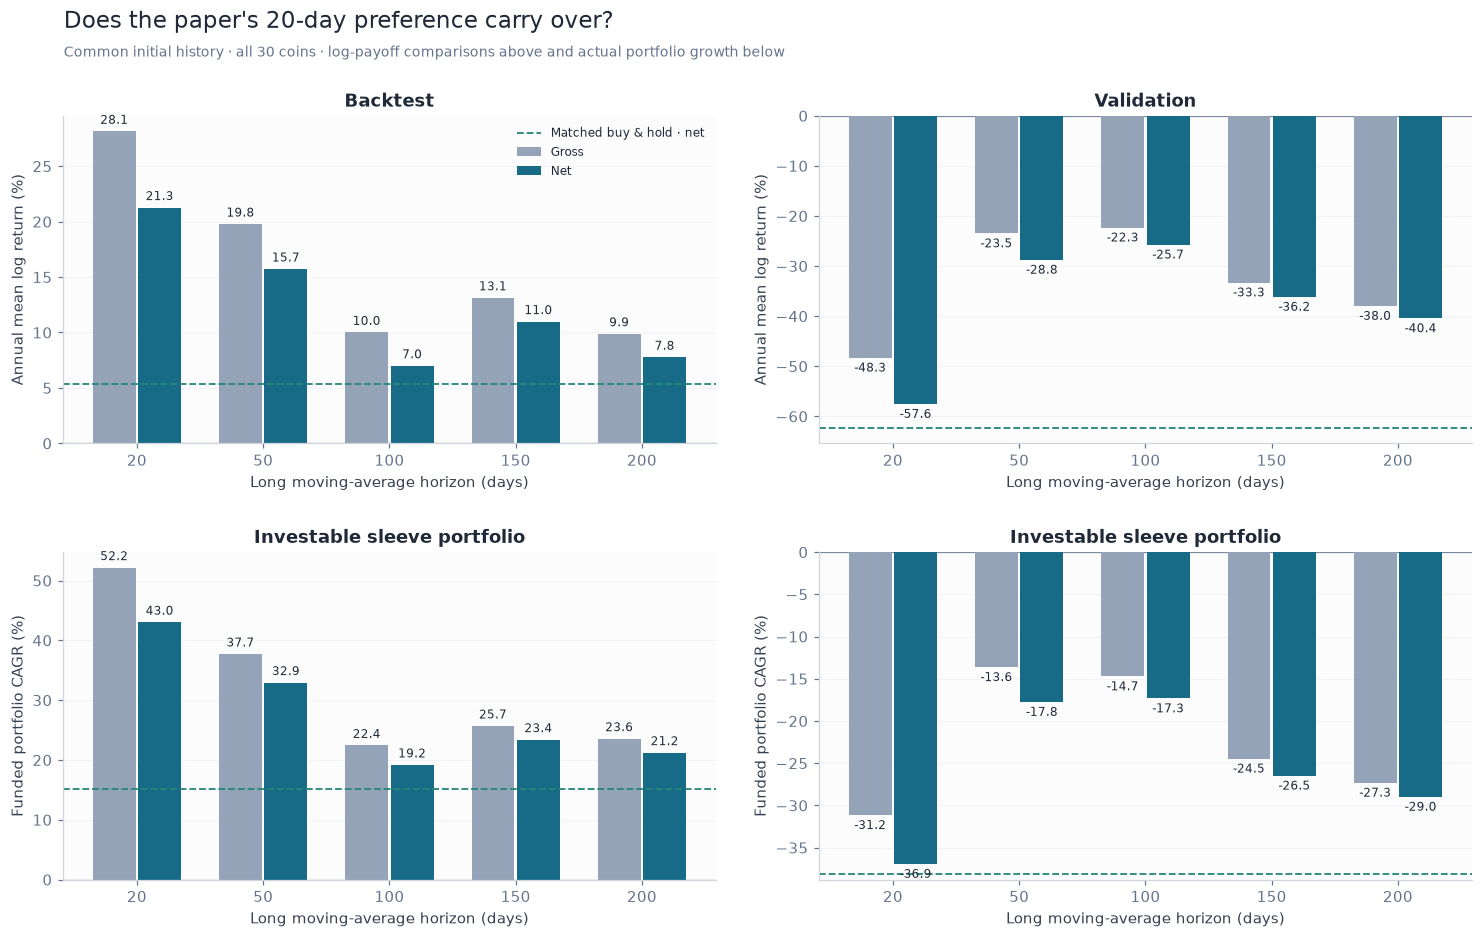

In [8]:
report_columns=["Cross-coin annual mean log (%)","Portfolio CAGR (%)","Portfolio Sharpe",
    "Portfolio max drawdown (%)","Mean invested (%)","Annual turnover","Annual fees (%)"]
display(winner_comparison)
for period in PERIOD_DATES:
    display(Markdown(f"### {period}: common-start comparison"))
    display(metrics.loc[(period,"common")].loc[PRIMARY_KEYS,report_columns].rename(index=LABELS,level="Strategy"))

#Top row: paper-style log payoff. Bottom row: growth of the actual funded portfolio.
fig,axes=plt.subplots(2,2,figsize=(14,8.7))
for col,period in enumerate(PERIOD_DATES):
    for row,metric,ylabel in [(0,"Cross-coin annual mean log (%)","Annual mean log return (%)"),
                              (1,"Portfolio CAGR (%)","Funded portfolio CAGR (%)")]:
        ax=axes[row,col]
        for offset,basis,color in [(-.18,"gross","#94a3b8"),(.18,"net","#176b87")]:
            values=[metrics.loc[(period,"common",k,basis),metric] for k in RULE_KEYS]
            bars=ax.bar(np.arange(5)+offset,values,.34,color=color,label=basis.capitalize())
            ax.bar_label(bars,fmt="%.1f",fontsize=8,padding=3)
        bm=metrics.loc[(period,"common","BH_MATCHED","net"),metric]
        ax.axhline(bm,color="#268779",ls="--",lw=1.2,label="Matched buy & hold · net")
        ax.set_xticks(range(5),LOOKBACKS);ax.set_xlabel("Long moving-average horizon (days)")
        ax.set_ylabel(ylabel);ax.set_title(period if row==0 else "Investable sleeve portfolio")
        polish_axis(ax,zero_line=True)
axes[0,0].legend(fontsize=8)
show_figure(fig,"horizon_comparison","Does the paper's 20-day preference carry over?","Common initial history · all 30 coins · log-payoff comparisons above and actual portfolio growth below")


### Trade-level context

Shorter averages can react sooner, but they can also trade more. Here we look at actual
turnover and completed holding periods, including the final exits at each period's end.


Completed coin trades  Mean holding days  \
Period     Strategy                                             
Backtest   VMA_20                     2063             8.5381   
           VMA_50                     1216            14.1579   
           VMA_100                     904            18.7212   
           VMA_150                     644            25.5311   
           VMA_200                     635            25.7717   
Validation VMA_20                     1188             6.4874   
           VMA_50                      676            10.2648   
           VMA_100                     440            14.5409   
           VMA_150                     368            15.9620   
           VMA_200                     317            18.3502   

                     Median holding days  Profitable trades (%)  \
Period     Strategy                                               
Backtest   VMA_20                 4.0000                23.8972   
           VMA_50                 4.0000                19.8191   
           VMA_100                4.0000                15.7080   
           VMA_150                4.0000                15.9938   
           VMA_200                4.0000                16.3780   
Validation VMA_20                 3.0000                16.2458   
           VMA_50                 3.0000                15.2367   
           VMA_100                4.0000                12.9545   
           VMA_150                3.0000                10.3261   
           VMA_200                3.0000                11.3565   

                     Median trade return (%)  Segment-end exits  \
Period     Strategy                                               
Backtest   VMA_20                    -2.8575                  1   
           VMA_50                    -3.4770                 10   
           VMA_100                   -3.7648                 26   
           VMA_150                   -3.9798                 27   
           VMA_200                   -4.0727                 27   
Validation VMA_20                    -3.3551                 10   
           VMA_50                    -3.4683                 26   
           VMA_100                   -3.7728                 26   
           VMA_150                   -4.4349                 19   
           VMA_200                   -4.7836                 17   

                     Annual turnover  Annual fees (%)  
Period     Strategy                                    
Backtest   VMA_20            31.4655           6.2931  
           VMA_50            17.5971           3.5194  
           VMA_100           13.2447           2.6489  
           VMA_150            9.2152           1.8430  
           VMA_200            8.8903           1.7781  
Validation VMA_20            44.3981           8.8796  
           VMA_50            24.5360           4.9072  
           VMA_100           15.7854           3.1571  
           VMA_150           13.1554           2.6311  
           VMA_200           11.1593           2.2319

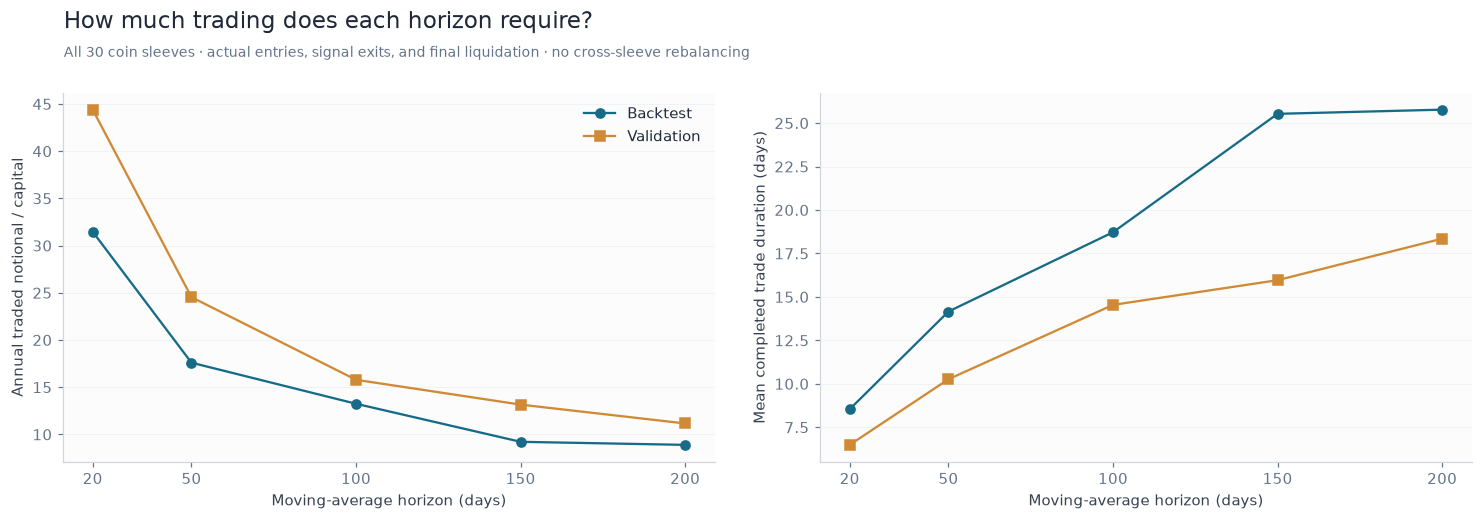

In [9]:
#How often are we trading, and how long do positions actually last?
trade_summary=[]
for period in PERIOD_DATES:
    for key in RULE_KEYS:
        result=accounts[(period,"common",key,"net")];trades=result["trades"]
        trade_summary.append({"Period":period,"Strategy":key,"Completed coin trades":len(trades),
            "Mean holding days":trades["Holding days"].mean(),
            "Median holding days":trades["Holding days"].median(),"Profitable trades (%)":100*(trades["Trade return"]>0).mean(),
            "Median trade return (%)":100*trades["Trade return"].median(),"Segment-end exits":int(trades["Exit reason"].eq("Segment end").sum()),
            "Annual turnover":365*result["daily"].turnover.mean(),"Annual fees (%)":36500*result["daily"].fee.mean()})
trade_summary=pd.DataFrame(trade_summary).set_index(["Period","Strategy"])
display(trade_summary)
fig,axes=plt.subplots(1,2,figsize=(14,4.8))
for period,color,marker in [("Backtest","#176b87","o"),("Validation","#d08a35","s")]:
    table=trade_summary.loc[period].reindex(RULE_KEYS)
    axes[0].plot(LOOKBACKS,table["Annual turnover"],marker=marker,color=color,label=period)
    axes[1].plot(LOOKBACKS,table["Mean holding days"],marker=marker,color=color,label=period)
axes[0].set_ylabel("Annual traded notional / capital");axes[1].set_ylabel("Mean completed trade duration (days)")
for ax in axes:ax.set_xticks(LOOKBACKS);ax.set_xlabel("Moving-average horizon (days)");polish_axis(ax)
axes[0].legend()
show_figure(fig,"turnover_and_duration","How much trading does each horizon require?","All 30 coin sleeves · actual entries, signal exits, and final liquidation · no cross-sleeve rebalancing")


## 6. Joint tests and coin-level evidence

The paper's joint test asks whether all coin means are zero. For daily coin log returns $Y$,
let $\widehat\mu$ be their means and $E=Y-\widehat\mu$:

$$V_{SUR}=E'E/T^2,\qquad W=\widehat\mu'V_{SUR}^{-1}\widehat\mu\sim\chi^2(30).$$

We also use **seven-lag HAC** covariance to allow short-run dependence. Both versions test
raw payoffs and paired differences against matched buy-and-hold.
A joint rejection can come from negative means too; it doesn't prove profitability.

The separate average-excess test asks whether the cross-coin advantage is positive.
Holm correction covers five horizons, or 150 coin–horizon tests for individual coins.
The intervals shown are nominal 95% HAC intervals.


### Backtest: net directional outperformance

,Annual mean log excess (pp),HAC SE annual (pp),95% lower (pp),95% upper (pp),HAC positive-excess p,Coins with positive excess,Holm positive-excess p
Strategy,,,,,,,
"VMA (1, 100)",1.6027,23.3704,-44.2033,47.4086,0.4727,12,1.0000
"VMA (1, 150)",5.5898,23.8397,-41.1361,52.3156,0.4073,17,1.0000
"VMA (1, 20)",15.8773,22.8582,-28.9248,60.6794,0.2437,21,1.0000
"VMA (1, 200)",2.3745,23.6798,-44.0379,48.7868,0.4601,16,1.0000
"VMA (1, 50)",10.3326,22.9810,-34.7101,55.3753,0.3265,22,1.0000


Joint zero-return tests (a rejection is not a directional profitability result):

Wald              p        Holm p         df    
Method       HAC     SUR    HAC    SUR    HAC    SUR HAC SUR
Strategy                                                    
VMA_20   19.3903 21.4010 0.9315 0.8749 1.0000 1.0000  30  30
VMA_50   18.2196 18.2075 0.9549 0.9551 1.0000 1.0000  30  30
VMA_100  19.6118 19.5038 0.9263 0.9288 1.0000 1.0000  30  30
VMA_150  19.7444 18.1897 0.9230 0.9554 1.0000 1.0000  30  30
VMA_200  20.8984 21.4134 0.8910 0.8745 1.0000 1.0000  30  30

### Validation: net directional outperformance

,Annual mean log excess (pp),HAC SE annual (pp),95% lower (pp),95% upper (pp),HAC positive-excess p,Coins with positive excess,Holm positive-excess p
Strategy,,,,,,,
"VMA (1, 100)",36.5281,33.6104,-29.3484,102.4045,0.1386,27,0.6928
"VMA (1, 150)",26.1170,34.3894,-41.2862,93.5202,0.2238,27,0.6928
"VMA (1, 20)",4.7208,33.8078,-61.5425,70.9842,0.4445,17,0.6928
"VMA (1, 200)",21.8308,33.7107,-44.2422,87.9038,0.2586,23,0.6928
"VMA (1, 50)",33.5151,33.9588,-33.0442,100.0744,0.1618,26,0.6928


Joint zero-return tests (a rejection is not a directional profitability result):

Wald              p        Holm p         df    
Method       HAC     SUR    HAC    SUR    HAC    SUR HAC SUR
Strategy                                                    
VMA_20   67.2688 44.8697 0.0001 0.0397 0.0006 0.1985  30  30
VMA_50   48.9677 39.2520 0.0158 0.1202 0.0633 0.4807  30  30
VMA_100  34.4909 28.5575 0.2616 0.5409 0.5233 1.0000  30  30
VMA_150  37.4301 31.8471 0.1649 0.3747 0.4948 1.0000  30  30
VMA_200  32.5905 25.9931 0.3406 0.6755 0.5233 1.0000  30  30

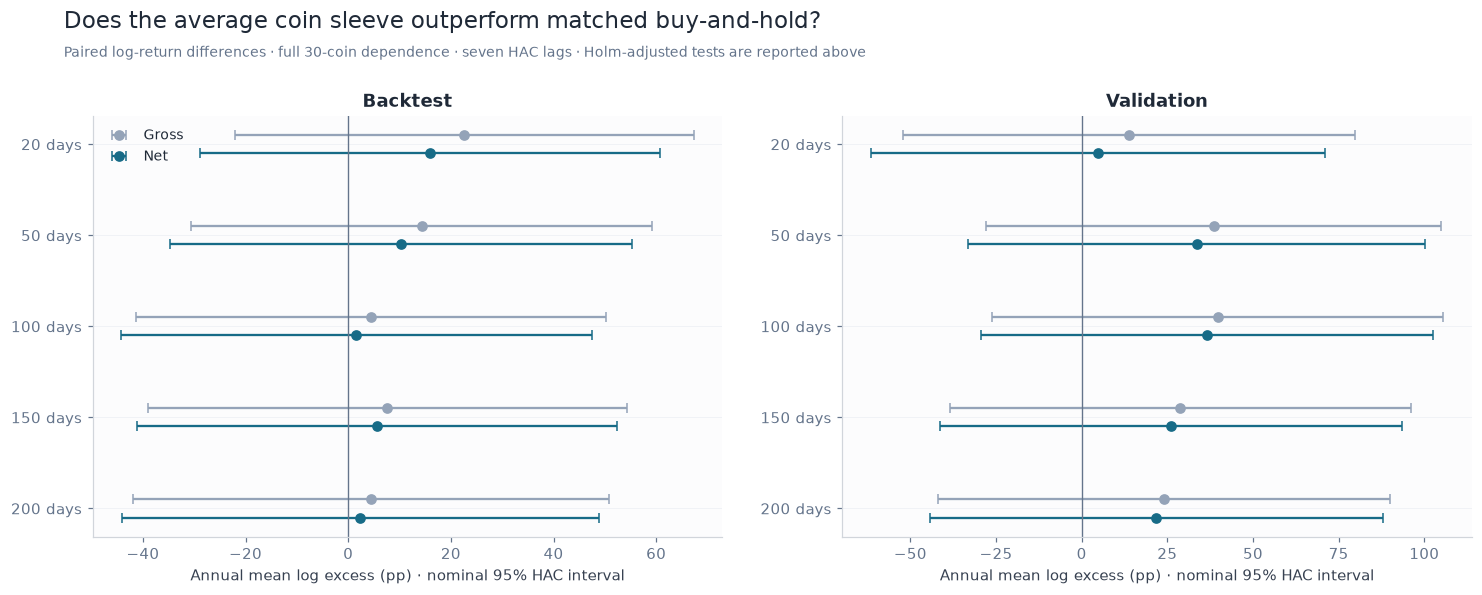

In [10]:
from scipy.stats import chi2, norm, t as student_t
from statsmodels.stats.multitest import multipletests

def mean_covariance(values,hac=False):
    #Y: daily coin-level log returns, with dates in rows and coins in columns.
    y=np.asarray(values,dtype=float);t_count=len(y)
    #mu_hat is the vector of coin means; e contains the deviations from those means.
    mean=y.mean(axis=0);e=y-mean
    #Sigma_hat: same-day covariance across coins before dividing by the number of dates.
    covariance=e.T@e/t_count
    #Add lagged covariance terms so short-run serial dependence also enters the uncertainty.
    if hac:
        for lag in range(1,min(HAC_LAGS,t_count-1)+1):
            #Bartlett weights give less weight to the more distant lags.
            gamma=e[lag:].T@e[:-lag]/t_count
            covariance+=(1-lag/(HAC_LAGS+1))*(gamma+gamma.T)
    #V: covariance of the estimated mean, not the covariance of a single daily observation.
    return mean,(covariance+covariance.T)/(2*t_count)

def joint_test(mean,covariance):
    #Check whether the joint covariance can support an ordinary inverse.
    rank=np.linalg.matrix_rank(covariance);n=len(mean)
    condition=np.linalg.cond(covariance)
    if rank!=n or not np.isfinite(condition) or condition>1e12:
        return np.nan,np.nan,rank,condition
    #W = mu_hat' V^(-1) mu_hat. A joint rejection can also come from negative means.
    w=float(mean@np.linalg.solve(covariance,mean))
    return w,float(chi2.sf(w,n)),rank,condition


#Keep the raw-return question separate from the paired buy-and-hold comparison.
joint_rows=[];average_rows=[];coin_rows=[]
for period in PERIOD_DATES:
    for basis in ["gross","net"]:
        benchmark=np.log1p(accounts[(period,"common","BH_MATCHED",basis)]["coin_returns"])
        for key in RULE_KEYS:
            logged=np.log1p(accounts[(period,"common",key,basis)]["coin_returns"])
            #Subtract the matched benchmark coin by coin and date by date.
            difference=logged-benchmark
            for hypothesis,values in [("Return vs zero",logged),("Difference vs buy & hold",difference)]:
                mean,cov=mean_covariance(values,hac=True)
                for method in ["SUR","HAC"]:
                    m,v=mean_covariance(values,hac=(method=="HAC"))
                    w,p,rank,condition=joint_test(m,v)
                    joint_rows.append({"Period":period,"Basis":basis,"Strategy":key,"Hypothesis":hypothesis,
                        "Method":method,"Wald":w,"p":p,"df":len(ASSETS),"Covariance rank":rank,"Condition number":condition})
                standard_error=np.sqrt(np.diag(cov))
                z=np.divide(mean,standard_error,out=np.full(len(mean),np.nan),where=standard_error>0)
                iid_se=values.std(ddof=1).to_numpy()/np.sqrt(len(values))
                for i,asset in enumerate(ASSETS):
                    coin_rows.append({"Period":period,"Basis":basis,"Strategy":key,"Hypothesis":hypothesis,"Asset":asset,
                        "Annual mean log (%)":36500*mean[i],"HAC z":z[i],"HAC p":2*norm.sf(abs(z[i])),
                        "IID t":mean[i]/iid_se[i] if iid_se[i]>0 else np.nan,
                        "IID p":2*student_t.sf(abs(mean[i]/iid_se[i]),len(values)-1) if iid_se[i]>0 else np.nan})
            avg=difference.mean(axis=1).to_numpy()
            mean,cov=mean_covariance(difference,hac=True)
            a=np.ones(len(ASSETS))/len(ASSETS)
            effect=float(a@mean);se=float(np.sqrt(a@cov@a));z=effect/se
            average_rows.append({"Period":period,"Basis":basis,"Strategy":key,
                "Annual mean log excess (pp)":36500*effect,"HAC SE annual (pp)":36500*se,
                "95% lower (pp)":36500*(effect-1.96*se),"95% upper (pp)":36500*(effect+1.96*se),
                "HAC positive-excess p":norm.sf(z),"Coins with positive excess":int((difference.mean()>0).sum())})
joint_tests=pd.DataFrame(joint_rows)
joint_tests["Holm p"]=joint_tests.groupby(["Period","Basis","Hypothesis","Method"])["p"].transform(lambda x:multipletests(x,method="holm")[1])
joint_tests=joint_tests.set_index(["Period","Basis","Strategy","Hypothesis","Method"]).sort_index()
average_tests=pd.DataFrame(average_rows)
average_tests["Holm positive-excess p"]=average_tests.groupby(["Period","Basis"])["HAC positive-excess p"].transform(lambda x:multipletests(x,method="holm")[1])
average_tests=average_tests.set_index(["Period","Basis","Strategy"]).sort_index()
coin_tests=pd.DataFrame(coin_rows)
coin_tests["Holm HAC p"]=coin_tests.groupby(["Period","Basis","Hypothesis"])["HAC p"].transform(lambda x:multipletests(x,method="holm")[1])
coin_tests=coin_tests.set_index(["Period","Basis","Strategy","Hypothesis","Asset"]).sort_index()
for period in PERIOD_DATES:
    display(Markdown(f"### {period}: net directional outperformance"))
    display(average_tests.loc[(period,"net")].rename(index=LABELS))
    display(Markdown("Joint zero-return tests (a rejection is not a directional profitability result):"))
    table=joint_tests.xs((period,"net","Return vs zero"),level=("Period","Basis","Hypothesis"))
    display(table[["Wald","p","Holm p","df"]].unstack("Method").reindex(RULE_KEYS))

fig,axes=plt.subplots(1,2,figsize=(14,5.5))
for ax,period in zip(axes,PERIOD_DATES):
    for offset,basis,color in [(-.1,"gross","#94a3b8"),(.1,"net","#176b87")]:
        table=average_tests.loc[(period,basis)].reindex(RULE_KEYS)
        values=table["Annual mean log excess (pp)"].to_numpy()
        error=1.96*table["HAC SE annual (pp)"].to_numpy()
        ax.errorbar(values,np.arange(5)+offset,xerr=error,fmt="o",capsize=3,color=color,label=basis.capitalize())
    ax.axvline(0,color="#64748b",lw=.9);ax.set_yticks(range(5),[f"{n} days" for n in LOOKBACKS]);ax.invert_yaxis()
    ax.set_title(period);ax.set_xlabel("Annual mean log excess (pp) · nominal 95% HAC interval");polish_axis(ax)
axes[0].legend(fontsize=9)
show_figure(fig,"excess_return_inference","Does the average coin sleeve outperform matched buy-and-hold?","Paired log-return differences · full 30-coin dependence · seven HAC lags · Holm-adjusted tests are reported above")


### Coin results and BTC/ETH

Is the advantage spread across coins? Positive heatmap cells mean the rule beats that coin's
matched buy-and-hold log payoff. BTC and ETH are shown separately, keeping raw-return
and excess-return tests distinct.


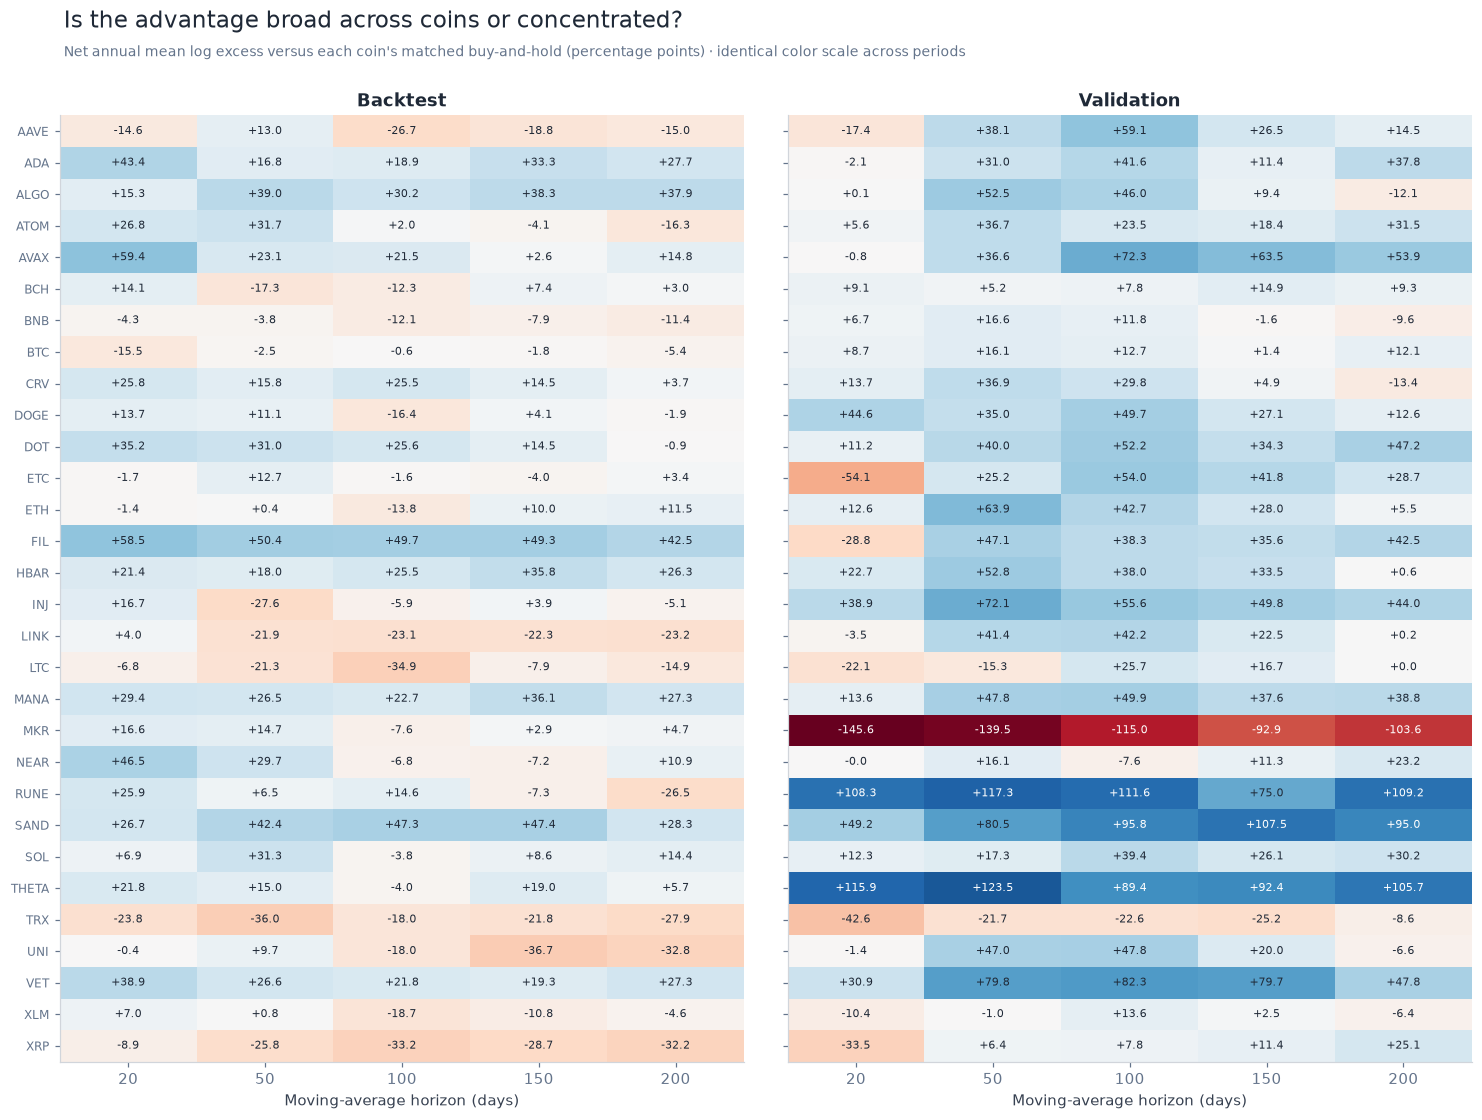

Annual mean log (%)  \
Period     Asset   Strategy Hypothesis                                      
Backtest   BTC-USD VMA_100  Difference vs buy & hold              -0.5728   
           ETH-USD VMA_100  Difference vs buy & hold             -13.7968   
           BTC-USD VMA_100  Return vs zero                        27.0549   
           ETH-USD VMA_100  Return vs zero                         1.2628   
           BTC-USD VMA_150  Difference vs buy & hold              -1.8044   
           ETH-USD VMA_150  Difference vs buy & hold              10.0407   
           BTC-USD VMA_150  Return vs zero                        25.8233   
           ETH-USD VMA_150  Return vs zero                        25.1003   
           BTC-USD VMA_20   Difference vs buy & hold             -15.4980   
           ETH-USD VMA_20   Difference vs buy & hold              -1.4064   
           BTC-USD VMA_20   Return vs zero                        12.1298   
           ETH-USD VMA_20   Return vs zero                        13.6531   
           BTC-USD VMA_200  Difference vs buy & hold              -5.3828   
           ETH-USD VMA_200  Difference vs buy & hold              11.5294   
           BTC-USD VMA_200  Return vs zero                        22.2449   
           ETH-USD VMA_200  Return vs zero                        26.5890   
           BTC-USD VMA_50   Difference vs buy & hold              -2.5265   
           ETH-USD VMA_50   Difference vs buy & hold               0.3790   
           BTC-USD VMA_50   Return vs zero                        25.1013   
           ETH-USD VMA_50   Return vs zero                        15.4386   
Validation BTC-USD VMA_100  Difference vs buy & hold              12.7098   
           ETH-USD VMA_100  Difference vs buy & hold              42.6632   
           BTC-USD VMA_100  Return vs zero                         0.7277   
           ETH-USD VMA_100  Return vs zero                        24.3942   
           BTC-USD VMA_150  Difference vs buy & hold               1.4123   
           ETH-USD VMA_150  Difference vs buy & hold              28.0205   
           BTC-USD VMA_150  Return vs zero                       -10.5697   
           ETH-USD VMA_150  Return vs zero                         9.7515   
           BTC-USD VMA_20   Difference vs buy & hold               8.6890   
           ETH-USD VMA_20   Difference vs buy & hold              12.6024   
           BTC-USD VMA_20   Return vs zero                        -3.2930   
           ETH-USD VMA_20   Return vs zero                        -5.6666   
           BTC-USD VMA_200  Difference vs buy & hold              12.0975   
           ETH-USD VMA_200  Difference vs buy & hold               5.4869   
           BTC-USD VMA_200  Return vs zero                         0.1154   
           ETH-USD VMA_200  Return vs zero                       -12.7821   
           BTC-USD VMA_50   Difference vs buy & hold              16.0577   
           ETH-USD VMA_50   Difference vs buy & hold              63.8889   
           BTC-USD VMA_50   Return vs zero                         4.0757   
           ETH-USD VMA_50   Return vs zero                        45.6198   

                                                      HAC p  Holm HAC p  
Period     Asset   Strategy Hypothesis                                   
Backtest   BTC-USD VMA_100  Difference vs buy & hold 0.9747      1.0000  
           ETH-USD VMA_100  Difference vs buy & hold 0.5691      1.0000  
           BTC-USD VMA_100  Return vs zero           0.1564      1.0000  
           ETH-USD VMA_100  Return vs zero           0.9535      1.0000  
           BTC-USD VMA_150  Difference vs buy & hold 0.9249      1.0000  
           ETH-USD VMA_150  Difference vs buy & hold 0.6824      1.0000  
           BTC-USD VMA_150  Return vs zero           0.1708      1.0000  
           ETH-USD VMA_150  Return vs zero           0.2184      1.0000  
           BTC-USD VMA_20   Difference vs buy & hold 0.3986      1.0000  
     

In [11]:
#A positive cell means this horizon beat that coin's matched buy-and-hold log payoff.
heatmaps={}
for period in PERIOD_DATES:
    heatmaps[period]=coin_tests.xs((period,"net","Difference vs buy & hold"),level=("Period","Basis","Hypothesis"))[
        "Annual mean log (%)"].unstack("Strategy").reindex(index=ASSETS,columns=RULE_KEYS)
#Both periods share one color scale so a similar color has the same meaning.
bound=max(np.abs(x.to_numpy()).max() for x in heatmaps.values())
fig,axes=plt.subplots(1,2,figsize=(14,10.4),sharey=True)
for ax,period in zip(axes,PERIOD_DATES):
    values=heatmaps[period].to_numpy()
    ax.imshow(values,cmap="RdBu",vmin=-bound,vmax=bound,aspect="auto")
    for (row,col),value in np.ndenumerate(values):
        ax.text(col,row,f"{value:+.1f}",ha="center",va="center",fontsize=7,color="white" if abs(value)>.6*bound else "#1f2937")
    ax.set_xticks(range(5),LOOKBACKS);ax.set_yticks(range(30),[a.replace("-USD","") for a in ASSETS],fontsize=8)
    ax.set_xlabel("Moving-average horizon (days)");ax.set_title(period)
show_figure(fig,"coin_excess_heatmap","Is the advantage broad across coins or concentrated?","Net annual mean log excess versus each coin's matched buy-and-hold (percentage points) · identical color scale across periods")
btc_eth=coin_tests.reset_index().query("Basis=='net' and Asset in ['BTC-USD','ETH-USD']").set_index(
    ["Period","Asset","Strategy","Hypothesis"])[["Annual mean log (%)","HAC p","Holm HAC p"]]
display(btc_eth)


## 7. Standardized daily performance

Same daily-return tables as Catching Crypto. BTC alpha uses a **20-lag HAC** regression,
separate from the seven-lag joint tests above. The alpha-to-residual-risk measure is called
**Appraisal ratio** here; the reference calls this calculation Information ratio.


In [12]:
#Same daily-return summaries as Catching Crypto, with paper-style payoff kept separately.
def performance(r, benchmark):
    r = r.dropna()
    benchmark = benchmark.reindex(r.index)
    aligned = pd.concat({"strategy":r, "benchmark":benchmark}, axis=1, sort=True).dropna()
    wealth, dd = wealth_drawdown(r)
    sd = r.std(ddof=1)
    downside = np.sqrt(np.mean(np.minimum(r, 0)**2))
    cagr = wealth.iloc[-1]**(365/len(r))-1
    fit = sm.OLS(aligned["strategy"].to_numpy(), sm.add_constant(aligned["benchmark"].to_numpy())).fit(
        cov_type="HAC", cov_kwds={"maxlags":min(BTC_HAC_LAGS,len(aligned)-1),"use_correction":True}, use_t=True)
    residual_sd = np.std(fit.resid, ddof=1)
    return {"N dates":len(r), "Total return (%)":100*(wealth.iloc[-1]-1), "CAGR (%)":100*cagr,
            "Volatility (%)":100*sd*np.sqrt(365), "Sharpe":np.sqrt(365)*r.mean()/sd if sd>0 else np.nan,
            "Sortino":np.sqrt(365)*r.mean()/downside if downside>0 else np.nan,
            "Max drawdown (%)":100*dd.min(), "Positive days (%)":100*(r>0).mean(),
            "Alpha vs BTC (%)":36500*fit.params[0], "Beta vs BTC":fit.params[1],
            "Alpha HAC p":fit.pvalues[0],
            "Appraisal ratio":fit.params[0]*np.sqrt(365)/residual_sd if residual_sd>1e-12 else np.nan,
            "Skewness":r.skew(), "Pearson kurtosis":r.kurt()+3}

CORE_METRICS = ["Total return (%)","CAGR (%)","Volatility (%)","Sharpe","Sortino",
                "Max drawdown (%)","Positive days (%)","Annual turnover"]
INSTITUTIONAL_METRICS = ["Alpha vs BTC (%)","Beta vs BTC","Alpha HAC p",
                         "Appraisal ratio","Skewness","Pearson kurtosis"]


standardized_rows=[]
for (period,mode,key,basis),result in accounts.items():
    row=performance(result["daily"]["return"],returns["BTC-USD"])
    row["Annual turnover"]=365*result["daily"].turnover.mean()
    standardized_rows.append({"Period":period,"Warm-up":mode,"Strategy":key,"Basis":basis,**row})
standardized_metrics=pd.DataFrame(standardized_rows).set_index(["Period","Warm-up","Strategy","Basis"]).sort_index()
for period in PERIOD_DATES:
    display(Markdown(f"### {period}: net daily performance"))
    table=standardized_metrics.xs((period,"common","net"),level=("Period","Warm-up","Basis")).reindex(PRIMARY_KEYS).rename(index=LABELS)
    display(table[CORE_METRICS])
    display(table[INSTITUTIONAL_METRICS])


### Backtest: net daily performance

,Total return (%),CAGR (%),Volatility (%),Sharpe,Sortino,Max drawdown (%),Positive days (%),Annual turnover
Strategy,,,,,,,,
"VMA (1, 20)",318.4947,43.0285,42.7956,1.0507,1.5708,-49.8207,40.6164,31.4655
"VMA (1, 50)",212.2919,32.9353,44.6847,0.8612,1.2726,-55.4116,41.7123,17.5971
"VMA (1, 100)",101.6845,19.1703,44.7747,0.6166,0.8912,-64.8580,41.3014,13.2447
"VMA (1, 150)",131.8015,23.3897,43.7624,0.7003,1.0098,-59.9836,43.0822,9.2152
"VMA (1, 200)",115.9425,21.2229,44.0923,0.6585,0.9372,-63.0100,43.2192,8.8903
Buy & hold · matched start,75.4994,15.0983,69.9839,0.5554,0.7734,-86.7373,45.4110,0.4973
Buy & hold · full segment,845.3475,75.3468,87.1301,1.0885,1.5543,-89.6841,54.4521,0.4979


,Alpha vs BTC (%),Beta vs BTC,Alpha HAC p,Appraisal ratio,Skewness,Pearson kurtosis
Strategy,,,,,,
"VMA (1, 20)",29.3873,0.3242,0.1940,0.7774,-0.0106,9.5805
"VMA (1, 50)",21.5349,0.3526,0.3518,0.5523,-0.0669,9.2281
"VMA (1, 100)",10.7853,0.3501,0.6339,0.2753,-0.1938,10.3633
"VMA (1, 150)",13.8015,0.3505,0.5261,0.3631,-0.2663,9.5366
"VMA (1, 200)",11.4300,0.3663,0.5989,0.3022,-0.3621,9.1213
Buy & hold · matched start,0.8530,0.7910,0.9747,0.0171,-0.4140,6.7447
Buy & hold · full segment,41.1530,1.1172,0.2163,0.7761,-0.4243,7.6699


### Validation: net daily performance

,Total return (%),CAGR (%),Volatility (%),Sharpe,Sortino,Max drawdown (%),Positive days (%),Annual turnover
Strategy,,,,,,,,
"VMA (1, 20)",-54.5908,-36.9374,33.4734,-1.2078,-1.5758,-62.9111,46.4000,44.3981
"VMA (1, 50)",-28.4504,-17.7586,31.0579,-0.4745,-0.6647,-45.6803,46.7200,24.5360
"VMA (1, 100)",-27.8211,-17.3369,32.3687,-0.4253,-0.5705,-45.1269,43.5200,15.7854
"VMA (1, 150)",-40.9579,-26.4880,31.4866,-0.8173,-1.0419,-52.8222,44.9600,13.1554
"VMA (1, 200)",-44.3545,-28.9881,31.9159,-0.9089,-1.1310,-56.1966,46.5600,11.1593
Buy & hold · matched start,-56.0327,-38.1146,62.6899,-0.4487,-0.6123,-71.3340,49.7600,1.1871
Buy & hold · full segment,-56.0327,-38.1146,62.6899,-0.4487,-0.6123,-71.3340,49.7600,1.1871


,Alpha vs BTC (%),Beta vs BTC,Alpha HAC p,Appraisal ratio,Skewness,Pearson kurtosis
Strategy,,,,,,
"VMA (1, 20)",-39.4817,0.4287,0.0745,-1.4230,-0.5236,12.6944
"VMA (1, 50)",-13.9680,0.3470,0.4343,-0.5153,0.2660,10.9388
"VMA (1, 100)",-13.0136,0.3399,0.4506,-0.4524,-0.4897,10.6126
"VMA (1, 150)",-24.9783,0.3408,0.1720,-0.9003,-1.1847,14.1973
"VMA (1, 200)",-28.1701,0.3792,0.1125,-1.0326,-1.8180,19.9818
Buy & hold · matched start,-25.4290,1.2201,0.2730,-0.7704,-0.2864,6.8914
Buy & hold · full segment,-25.4290,1.2201,0.2730,-0.7704,-0.2864,6.8914


### Representative accounts

We plot the selected rule, the authors' 20-day rule, and matched buy-and-hold.
If the first two coincide, one line is enough. The dashed curve is the selected rule before costs.


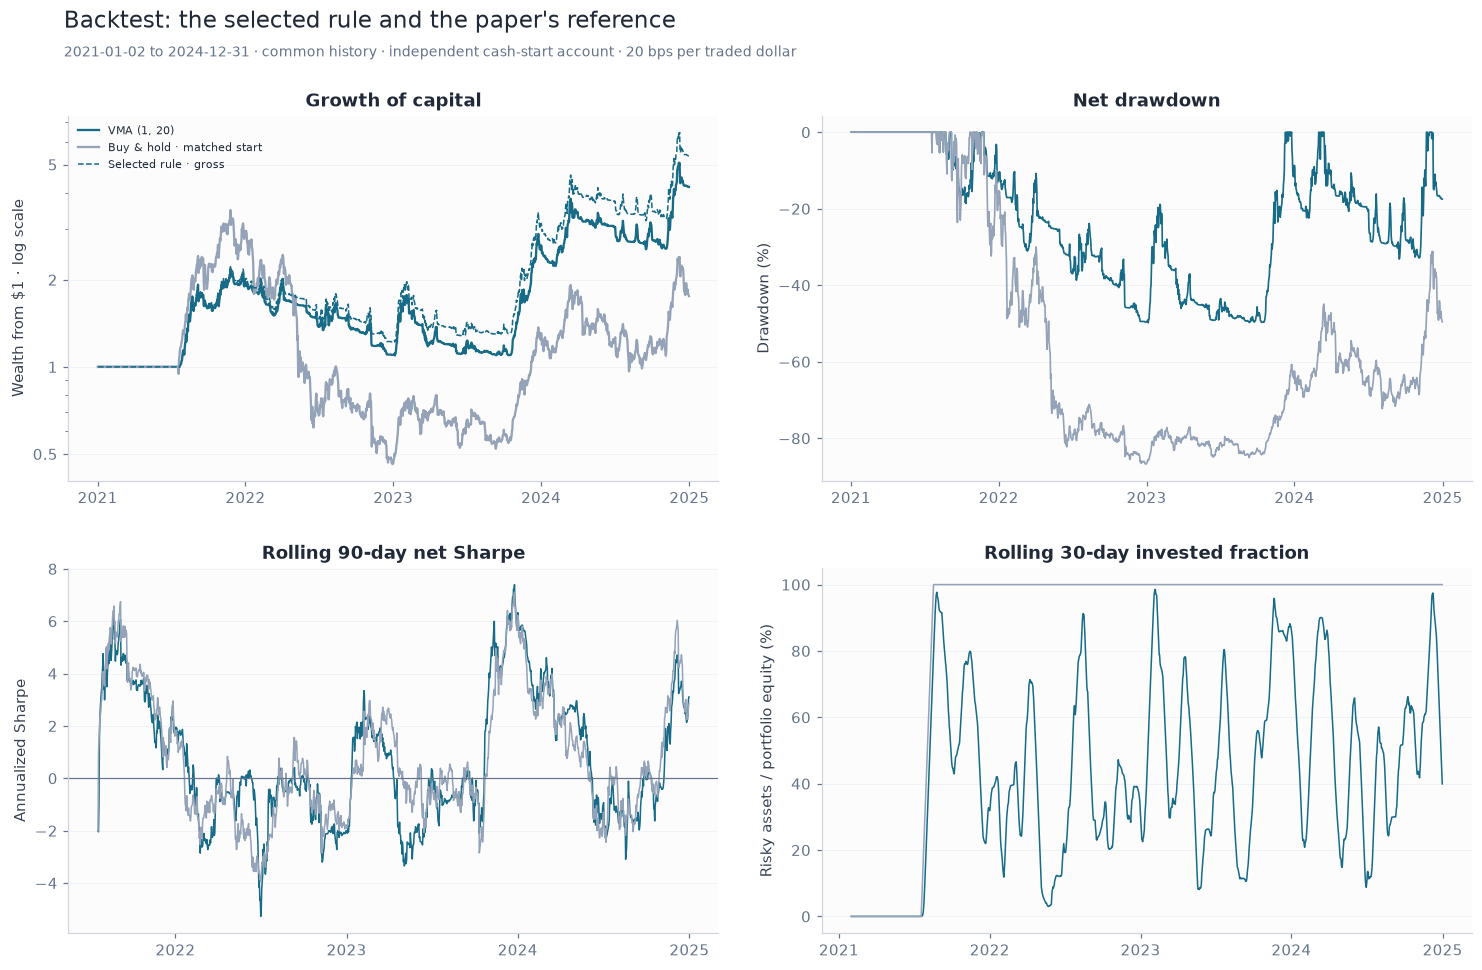

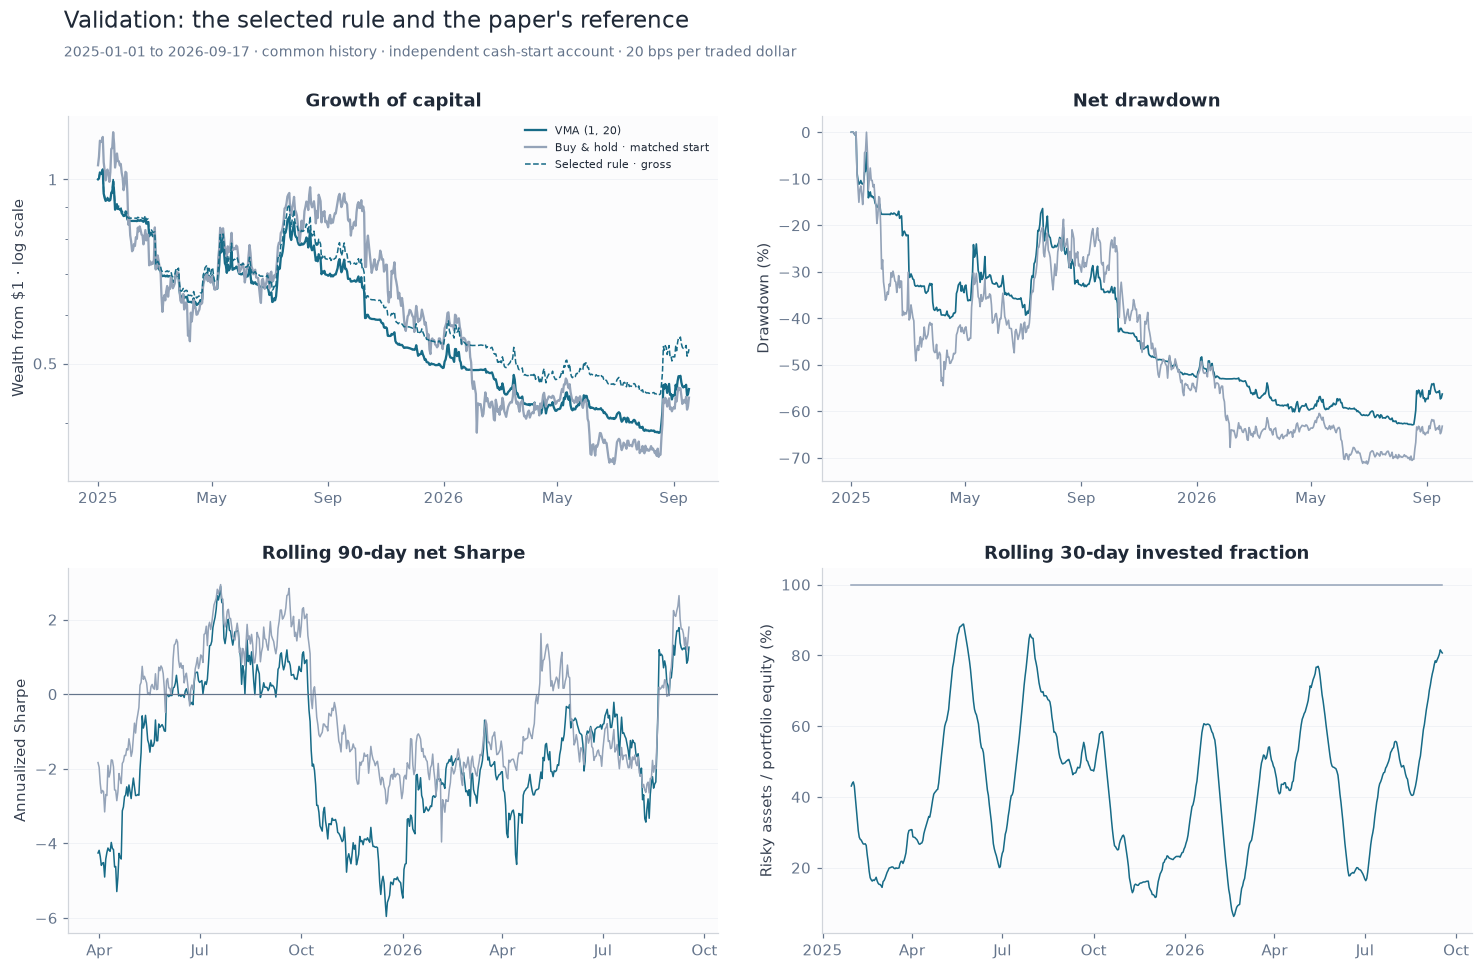

In [13]:
#If the selected horizon is already 20 days, show it only once.
focus_rules=list(dict.fromkeys(["VMA_20",selected_key]))
focus_keys=focus_rules+["BH_MATCHED"]
from matplotlib.ticker import LogLocator, FuncFormatter, NullFormatter
for period,dates in PERIOD_DATES.items():
    fig,axes=plt.subplots(2,2,figsize=(14,9))
    for key in focus_keys:
        frame=accounts[(period,"common",key,"net")]["daily"]
        color=RULE_COLORS.get(key,"#94a3b8")
        wealth,dd=wealth_drawdown(frame["return"])
        axes[0,0].plot(dates,wealth,color=color,lw=1.5,label=LABELS[key])
        axes[0,1].plot(dates,dd*100,color=color,lw=1.1)
        #Rolling Sharpe uses the daily net portfolio return over the latest 90 dates.
        roll=frame["return"].rolling(90,min_periods=90)
        axes[1,0].plot(dates,np.sqrt(365)*roll.mean()/roll.std(),color=color,lw=1)
        axes[1,1].plot(dates,100*frame.gross_exposure.rolling(30,min_periods=30).mean(),color=color,lw=1)
    gross=accounts[(period,"common",selected_key,"gross")]["daily"]
    axes[0,0].plot(dates,gross.nav,color=RULE_COLORS[selected_key],ls="--",lw=1,label="Selected rule · gross")
    axes[0,0].set_yscale("log")
    axes[0,0].yaxis.set_major_locator(LogLocator(base=10,subs=(1,2,5)))
    axes[0,0].yaxis.set_major_formatter(FuncFormatter(lambda value,position:f"{value:g}"))
    axes[0,0].yaxis.set_minor_formatter(NullFormatter())
    axes[0,0].legend(fontsize=7)
    for ax,title,ylabel in [(axes[0,0],"Growth of capital","Wealth from $1 · log scale"),
        (axes[0,1],"Net drawdown","Drawdown (%)"),(axes[1,0],"Rolling 90-day net Sharpe","Annualized Sharpe"),
        (axes[1,1],"Rolling 30-day invested fraction","Risky assets / portfolio equity (%)")]:
        ax.set_title(title);ax.set_ylabel(ylabel);polish_axis(ax,date_axis=True)
    axes[1,0].axhline(0,color="#64748b",lw=.8)
    show_figure(fig,f"{period.lower()}_performance",f"{period}: the selected rule and the paper's reference",f"{dates[0].date()} to {dates[-1].date()} · common history · independent cash-start account · 20 bps per traded dollar")


### Backtest-to-validation comparison

How much of the backtest Sharpe carries over? Keep all five horizons in view.
The selected rule stays fixed, even if another horizon looks better in validation.


,Backtest Sharpe,Validation Sharpe,Sharpe change,Selected in backtest
Strategy,,,,
"VMA (1, 20)",1.0507,-1.2078,-2.2586,True
"VMA (1, 50)",0.8612,-0.4745,-1.3356,False
"VMA (1, 100)",0.6166,-0.4253,-1.0419,False
"VMA (1, 150)",0.7003,-0.8173,-1.5176,False
"VMA (1, 200)",0.6585,-0.9089,-1.5674,False


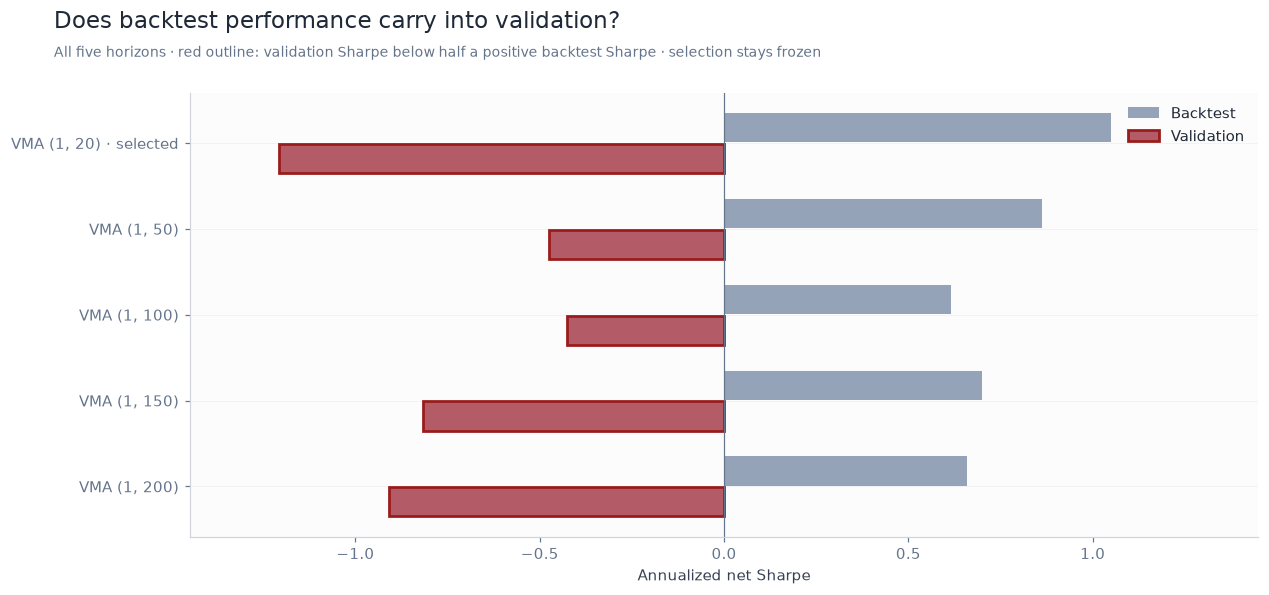

In [14]:
#Keep all five horizons in view. Validation does not choose a replacement strategy.
generalization_table=pd.DataFrame({
    "Backtest Sharpe":[metrics.loc[("Backtest","common",k,"net"),"Portfolio Sharpe"] for k in RULE_KEYS],
    "Validation Sharpe":[metrics.loc[("Validation","common",k,"net"),"Portfolio Sharpe"] for k in RULE_KEYS],
},index=pd.Index(RULE_KEYS,name="Strategy"))
generalization_table["Sharpe change"]=generalization_table["Validation Sharpe"]-generalization_table["Backtest Sharpe"]
generalization_table["Selected in backtest"]=generalization_table.index==selected_key
display(generalization_table.rename(index=LABELS))
fig,ax=plt.subplots(figsize=(12,5.5))
y=np.arange(len(RULE_KEYS))
ax.barh(y-.18,generalization_table["Backtest Sharpe"],.34,color="#94a3b8",label="Backtest")
values=generalization_table["Validation Sharpe"]
bars=ax.barh(y+.18,values,.34,color=np.where(values>=0,"#268779","#b35b66"),label="Validation")
for bar,bt,val in zip(bars,generalization_table["Backtest Sharpe"],values):
    if bt>0 and val<.5*bt:
        bar.set_edgecolor("#991b1b");bar.set_linewidth(1.8)
limit=max(abs(generalization_table[["Backtest Sharpe","Validation Sharpe"]].to_numpy()).max()*1.2,.1)
ax.set_xlim(-limit,limit)
ax.set_yticks(y,[LABELS[k]+(" · selected" if k==selected_key else "") for k in RULE_KEYS])
ax.invert_yaxis();ax.set_xlabel("Annualized net Sharpe");ax.legend()
polish_axis(ax);ax.axvline(0,color="#64748b",lw=.8)
show_figure(fig,"backtest_validation","Does backtest performance carry into validation?",
            "All five horizons · red outline: validation Sharpe below half a positive backtest Sharpe · selection stays frozen")


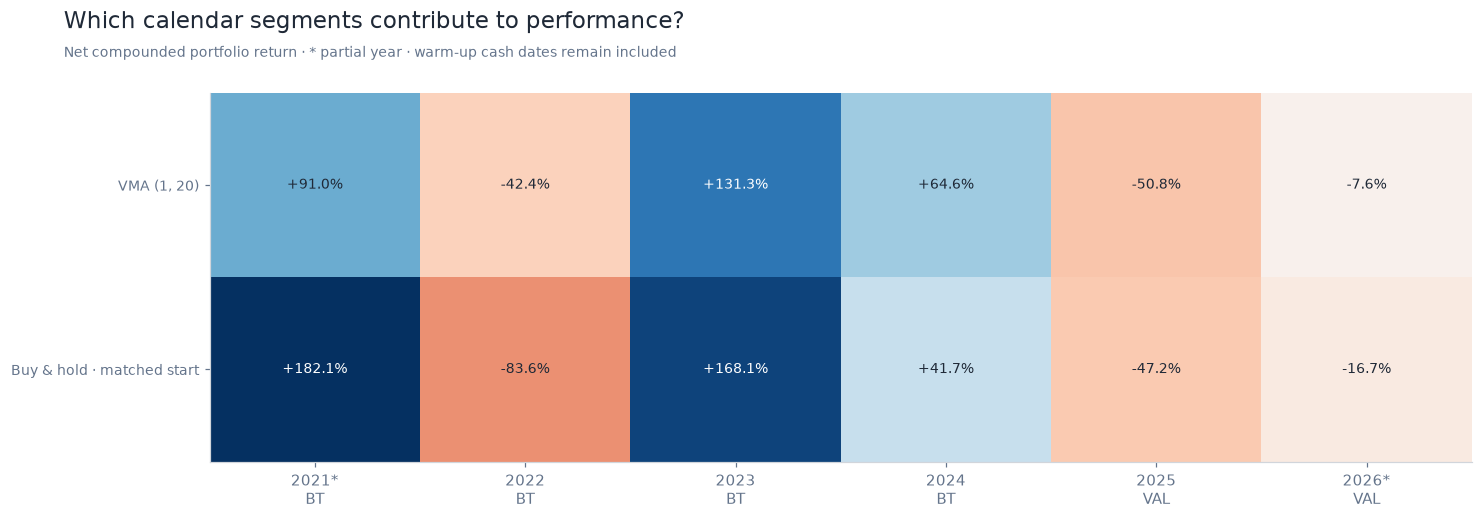

In [15]:
#Calendar returns compound only the dates present in each year and segment.
calendar_rows=[]
for period in PERIOD_DATES:
    for key in focus_keys:
        frame=accounts[(period,"common",key,"net")]["daily"]
        for year,block in frame.groupby(frame.index.year):
            calendar_rows.append({"Period":period,"Year":year,"Strategy":key,"Dates":len(block),
                "Net return (%)":100*((1+block["return"]).prod()-1)})
calendar_returns=pd.DataFrame(calendar_rows).set_index(["Period","Year","Strategy"]).sort_index()
wide=calendar_returns["Net return (%)"].unstack("Strategy").reindex(columns=focus_keys)
values=wide.to_numpy().T;bound=max(abs(values).max(),1.)
fig,ax=plt.subplots(figsize=(14,4.8))
ax.imshow(values,cmap="RdBu",vmin=-bound,vmax=bound,aspect="auto")
for (row,col),v in np.ndenumerate(values):ax.text(col,row,f"{v:+.1f}%",ha="center",va="center",fontsize=9,color="white" if abs(v)>.6*bound else "#1f2937")
labels=[]
for period,year in wide.index:
    days=calendar_returns.loc[(period,year)].iloc[0]["Dates"]
    full=366 if pd.Timestamp(year,12,31).is_leap_year else 365
    labels.append(f"{year}{'*' if days!=full else ''}\n{'BT' if period=='Backtest' else 'VAL'}")
ax.set_xticks(range(len(labels)),labels);ax.set_yticks(range(len(focus_keys)),[LABELS[k] for k in focus_keys],fontsize=9)
show_figure(fig,"calendar_returns","Which calendar segments contribute to performance?","Net compounded portfolio return · * partial year · warm-up cash dates remain included")


## 8. Reproducible research outputs

Save the full comparisons, daily returns, trades, and frozen selection. The manifest records
the input hash, dates, assumptions, and software versions. Failed horizons stay in the exports too.


In [16]:
#Keep the rules, input hashes and frozen selection together so this run can be identified.
specification={"study":"grobys_vma_rules","assets":ASSETS,"lookbacks":LOOKBACKS,"short_average":1,
    "logarithm":"natural","signal":"log close > inclusive trailing mean log close; next daily return",
    "sample_start":SAMPLE_START,"sample_end":SAMPLE_END,"calendar_convention":"explicit boundaries matching Catching Crypto",
    "split":{p:{"start":str(d[0].date()),"end":str(d[-1].date()),"dates":len(d)} for p,d in PERIOD_DATES.items()},
    "primary_warmup":COMMON_WARMUP,"sensitivity":"native horizon, same return calendar",
    "portfolio":"30 equally funded independent coin/cash sleeves; no cross-sleeve rebalancing",
    "cost_bps_per_side":COST_BPS,"entry":"post-fee asset value cash/(1+cost)","cash_yield":0,
    "final_liquidation":True,"primary_benchmark":"matched-start static buy and hold",
    "HAC_lags":HAC_LAGS,"BTC_regression_HAC_lags":BTC_HAC_LAGS,"multiplicity":"Holm across 5 horizons; individual tests across 150 coin-horizon pairs",
    "selection":frozen_selection,"input_sha256":input_hashes}
#Record the specification ID in the manifest; exports use the same readable folder on each run.
run_id=hashlib.sha256(json.dumps(specification,sort_keys=True).encode()).hexdigest()[:12]
OUTPUT_DIR=OUTPUT_ROOT
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
daily_export=pd.concat({k:v["daily"] for k,v in accounts.items()},names=["Period","Warm-up","Strategy","Basis","Return date"])
#Export the complete comparisons, including horizons that did not win.
for name,obj in {"daily_portfolio_returns":daily_export,"metrics":metrics,"backtest_ranking":ranking,
    "winner_comparison":winner_comparison,"standardized_performance":standardized_metrics,
    "generalization":generalization_table,
    "joint_tests":joint_tests,"average_excess_tests":average_tests,"coin_tests":coin_tests,
    "trade_summary":trade_summary,"calendar_returns":calendar_returns,
    "split":split_table,"verification":verification}.items():
    obj.to_csv(OUTPUT_DIR/(name+(".csv.gz" if name=="daily_portfolio_returns" else ".csv")))
for field in ["coin_returns","coin_nav"]:
    pd.concat({k:v[field] for k,v in accounts.items()},names=["Period","Warm-up","Strategy","Basis","Return date"]).to_csv(OUTPUT_DIR/f"{field}.csv.gz")
pd.concat({k:v["trades"] for k,v in accounts.items()},names=["Period","Warm-up","Strategy","Basis","Trade number"]).to_csv(OUTPUT_DIR/"completed_trades.csv.gz")
for field in ["holding_weights","sleeve_allocations","pnl_contributions","fee_contributions","traded_notional"]:
    pd.concat({(p,k):accounts[(p,"common",k,"net")][field] for p in PERIOD_DATES for k in focus_keys},
        names=["Period","Strategy","Return date"]).to_csv(OUTPUT_DIR/f"primary_{field}.csv.gz")
pd.concat({(mode,key):v for mode,group in signals.items() for key,v in group.items()},
          names=["Warm-up","Strategy","Formation date"]).to_csv(OUTPUT_DIR/"formation_signals.csv.gz")
(OUTPUT_DIR/"frozen_selection.json").write_text(json.dumps(frozen_selection,indent=2))
#Record software versions and the notebook source as well as the numerical results.
manifest={"run_id":run_id,"specification":specification,"checks_passed":len(verification),"figures":list(FIGURES),
    "environment":{"python":platform.python_version(),"numpy":np.__version__,"pandas":pd.__version__,"statsmodels":sm.__version__},
    "notebook_source_sha256":hashlib.sha256(json.dumps([c["source"] for c in json.loads((NOTEBOOK_DIR/NOTEBOOK_NAME).read_text())["cells"]],sort_keys=True).encode()).hexdigest()}
(OUTPUT_DIR/"manifest.json").write_text(json.dumps(manifest,indent=2))
for name,fig in FIGURES.items():fig.savefig(OUTPUT_DIR/f"{name}.png",dpi=160,bbox_inches="tight")
print(f"Saved {len(accounts)} accounts and {len(FIGURES)} figures to {OUTPUT_DIR.relative_to(NOTEBOOK_DIR).as_posix()}/")


Saved 48 accounts and 9 figures to output/technical_trading_rules/


## 9. Core findings and interpretation

The summary below uses the current frozen rule and computed validation rankings. The primary selection criterion is mean cross-coin net log return; CAGR and Sharpe describe the funded portfolio and need not give the same ranking.

Compare relative performance with the paired tests: outperforming buy-and-hold does not establish a positive return or positive alpha. These results depend on the fixed surviving universe, close-based execution, warm-up convention, costs, and zero cash yield. Validation has already been examined and remains historical evidence.


In [17]:
# Keep the conclusion tied to this run's rule selection and performance tables.
conclusion_metrics = pd.read_csv(OUTPUT_DIR / "metrics.csv")
conclusion_primary = conclusion_metrics.loc[conclusion_metrics["Warm-up"].eq("common") & conclusion_metrics.Basis.eq("net") & conclusion_metrics.Strategy.str.startswith("VMA_")]
conclusion_validation = conclusion_primary.loc[conclusion_primary.Period.eq("Validation")]
conclusion_best = conclusion_validation.sort_values("Cross-coin annual mean log (%)", ascending=False).iloc[0]
display(Markdown(f"**Frozen backtest rule:** {frozen_selection['strategy']}. "
                 f"**Highest observed validation mean log payoff:** {conclusion_best.Strategy}. "
                 f"{int(conclusion_validation['Portfolio CAGR (%)'].lt(0).sum())} of "
                 f"{len(conclusion_validation)} rules have negative validation CAGRs."))
display(conclusion_primary.loc[conclusion_primary.Strategy.eq(frozen_selection['strategy']),
    ["Period", "Strategy", "Portfolio CAGR (%)", "Portfolio Sharpe", "Portfolio max drawdown (%)"]].round(3))


**Frozen backtest rule:** VMA_20. **Highest observed validation mean log payoff:** VMA_100. 5 of 5 rules have negative validation CAGRs.

,Period,Strategy,Portfolio CAGR (%),Portfolio Sharpe,Portfolio max drawdown (%)
9,Backtest,VMA_20,43.0280,1.0510,-49.8210
33,Validation,VMA_20,-36.9370,-1.2080,-62.9110
